# Who Makes Money While Wall Street Sleeps?

*ADA 2026 - Milestone P3.* The full project proposal is in the [README](README.md).

## Introduction

Over the last decades, almost all of the gains of the US stock market seem to have been made **overnight**, between the close and the next open, while the **trading day** itself, when almost all trading, news reaction and price discovery happen, earned close to nothing. If returns reward risk or new information, both halves of the day should earn something. So who makes money while Wall Street sleeps?

We treat this anomaly as an investigation. We first establish the facts in our data (**the crime**), then interrogate three suspects: **risk** (do longer nights pay more?), **news** (do announcements land after the close?) and **the crowd** (does a burst of attention produce an overnight gain followed by an intraday "hangover"?). Tickers that look almost identical to famous ones provide a natural experiment (**the proof**), and the final verdict comes in P3.

**Research questions**
1. Do overnight returns exceed intraday returns across US stocks and ETFs, and does the gap survive data cleaning and statistical testing?
2. Risk: do longer market closures (weekends, holidays) earn higher overnight returns?
3. News: are corporate announcements (SEC 8-K filings) concentrated after the close, and do nights without announcements still earn more?
4. Crowd: after an attention spike (abnormal volume, Google Trends), do we observe an overnight gain followed by an intraday loss?
5. Proof: after a famous company's attention spikes, does a stock mistaken for it gain more than usual overnight, compared with placebo stocks?

**Roadmap:** Part I - The Data · Part II - The Crime · Part III - The Risk Suspect · Part IV - The News Suspect · Part V - The Crowd Suspect · Part VI - The Proof.

## Quickstart

1. Python 3.10 or newer, then `pip install -r requirements.txt`.
2. Run the first python cells of the notebook to download the Kaggle files (about 520 MB) and build the price table.
3. The SEC filings (`external/edgar/`) and the macro release dates (`external/macro/`) used in Part IV are in the repository. To download the filings again (about 20 minutes), the SEC asks for a name and an email:

```bash
SEC_USER_AGENT="Your Name your.email@epfl.ch" python -m scripts.collect_news
```

# Part I - The Data

This part describes how we handle a dataset of this size, what it contains, and why each transformation is needed. Every later part uses the table produced here.

## I.1 Reproducing the data

- `download_data()`: downloads the raw CSVs from Kaggle into `data/`.
- `build_prices()`: cleans them and writes `data/prices.parquet`.
- `load_prices()`: loads the table used by every part.

`data/` is not versioned. First run: ~520 MB download, 1–2 min build.

In [41]:
%load_ext autoreload
%autoreload 2

from src.analysis.crime import (
    crime_headline,
    filter_comparison,
    gap_bootstrap,
    gap_regression,
    gap_robustness,
    etf_kind_books,
    gap_share_above_zero,
    liquidity_quintiles,
    make_books,
    night_ahead_share,
    night_day_gap_by_ticker,
    portfolio_headlines,
    portfolio_paths,
    rolling_annualised,
    study_portfolios,
    ticker_wealth,
)
from src.analysis.overview import (
    adjustment_example,
    first_dates,
    missing_values,
    night_day_correlation,
    removed_rows_summary,
    return_stats,
    size_report,
    stale_among_zero_volume,
    tickers_per_year,
    volume_summary,
)
from src.config import STUDY_START_YEAR
from src.data.load import build_prices, download_data, load_prices
from src.data.metadata import (
    commodity_vol_etfs,
    etf_exclusion_counts,
    etf_kinds,
    exchange_breakdown,
    load_metadata,
    tag_special_etfs,
)
from src.data.quality import (
    FILTERS,
    filter_summary,
    flag_count_by_year,
    flag_suspicious,
    splice_examples,
    stale_share_by_liquidity,
    suspicious_share_by_year,
)
from src.data.sample import exclusion_waterfall, study_sample, unlinked_stocks
from src.features.returns import add_dollar_volume, add_price_night, add_returns
from src.visualization.plots import (
    plot_filter_comparison,
    plot_gap_histogram,
    plot_return_distributions,
    plot_rolling_means,
    plot_suspicious_share,
    plot_tickers_per_year,
    plot_volume_distribution,
    plot_wealth,
    plot_wealth_grid,
    set_style,
)

# Used in Part V.
from src.analysis.crowd import event_study, plot_event_study
from src.features.volume import abnormal_volume

set_style()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
download_data()
build_prices()
prices = load_prices()

## I.2 Source and format

*Stock Market Dataset* (Oleh Onyshchak, Kaggle): daily prices of all Nasdaq-traded stocks and ETFs, from 1962 to 1 April 2020. One CSV per ticker with `Date, Open, High, Low, Close, Adj Close, Volume`; `Adj Close` is adjusted for splits and dividends. Tickers per listing exchange:

In [43]:
meta = load_metadata()
exchange_breakdown(meta)

,stock,etf,total
exchange,,,
Nasdaq,2988,395,3383
NYSE,2520,0,2520
NYSE Arca,107,1435,1542
Cboe BZX,17,334,351
NYSE American,252,1,253
total,5884,2165,8049


Processed format: one row per (ticker, date). Raw `open` and `close` are kept to detect stale opens (I.6).

In [44]:
display(prices.head())
prices.dtypes

,ticker,date,open,close,open_adj,high_adj,low_adj,close_adj,volume,asset_type
0,A,1999-11-18,32.546494,31.473534,27.991459,30.759848,24.607878,27.068665,62546300,stock
1,A,1999-11-19,30.713520,28.880543,26.415020,26.453470,24.492531,24.838577,15234100,stock
2,A,1999-11-22,29.551144,31.473534,25.415323,27.068665,24.646326,27.068665,6577800,stock
3,A,1999-11-23,30.400572,28.612303,26.145872,26.837971,24.607880,24.607880,5975600,stock
4,A,1999-11-24,28.701717,29.372318,24.684778,25.799820,24.607878,25.261524,4843200,stock


ticker              category
date          datetime64[ns]
open                 float32
close                float32
open_adj             float32
high_adj             float32
low_adj              float32
close_adj            float32
volume                 Int64
asset_type          category
dtype: object

## I.3 Coverage over time

We count, for each year, the number of tickers with at least one trading day, for stocks and ETFs. This shows from which year the cross-section is large enough to support conclusions.

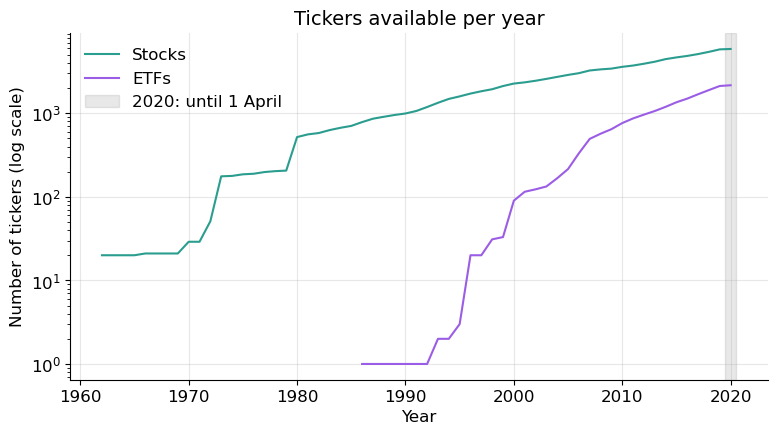

In [45]:
counts = tickers_per_year(prices)
fig = plot_tickers_per_year(counts)

In [46]:
# Decade snapshots plus the first and last complete years illustrate coverage.
counts.loc[[1962, 1970, 1980, 1990, 2000, 2010, 2019]]

,stock,etf
year,,
1962,20,0
1970,29,0
1980,519,0
1990,994,1
2000,2267,90
2010,3596,763
2019,5818,2121


Dates on which the most tickers have their first observation (many tickers starting on the same day reveal a change in data coverage):

In [47]:
first_dates(prices)

,n_tickers
first_date,
1980-03-17,257
1973-02-21,87
2017-10-26,39
1973-05-03,26
2000-01-03,25


**Takeaway:** In 1962 the file has 20 stocks; in 2019 it has 5,818 stocks and 2,121 ETFs (90 ETFs in 2000). The jumps are the data provider, not the market: 87 tickers start on 21 February 1973 and 257 on 17 March 1980. Before the 1980s the cross-section is a few firms that are still listed in 2020. The study period is set in I.6, from the quality of opening prices.

**Survivorship bias:** Only securities still listed in 2020 are in the file, so long-run average returns are likely biased upwards, and the overnight and the intraday return need not be affected the same way.

## I.4 Handling the size

We compare three ways of holding the data: the raw CSVs read with pandas default dtypes, the same CSVs read with optimised dtypes, and the processed Parquet file. CSV memory and loading time are measured on a random sample of 500 files and scaled to all files; the other figures are exact.

In [48]:
size = size_report()
display(size)
seconds = size["loading time (s)"]
print(
    f"Loading times on this run: {seconds['CSV, default dtypes']:.0f} s for the default CSV, "
    f"{seconds['CSV, optimised dtypes']:.0f} s for the optimised CSV, {seconds['Parquet']:.1f} s for Parquet. "
    "They change from one run to the next."
)

,rows,memory (GB),loading time (s),disk size (GB)
"CSV, default dtypes",28151758,6.03,23.96,2.75
"CSV, optimised dtypes",28151758,1.13,61.22,2.75
Parquet,28132072,1.24,0.42,0.71


Loading times on this run: 24 s for the default CSV, 61 s for the optimised CSV, 0.4 s for Parquet. They change from one run to the next.


**Choices:** ticker and asset_type are stored as category, prices as float32, and volume as nullable Int64. Parquet keeps these types, compresses the table, and can read only the columns or tickers we need.



**Takeaway:** Setting the dtypes cuts memory from 6.03 GB to 1.13 GB. Reading the optimised CSV is slower, because it also parses the dates; `build_prices()` pays that cost only once. Every later part then reads the Parquet file, which loads many times faster than the CSVs (times printed above) and takes 0.71 GB on disk instead of 2.75 GB. Its 1.24 GB in memory include the adjusted prices.

## I.5 Transformations

Two transformations turn raw prices into the quantities we study: prices are first adjusted for dividends, then split into an overnight and an intraday return.

**Adjusted prices:** `Open`, `High`, `Low` and `Close` are already adjusted for splits, not for dividends. On an ex-dividend day the price drop is not a loss for the shareholder. `Adj Close` accounts for both, so the same daily factor is applied to the other prices:

$$f_t = \frac{\text{Adj Close}_t}{\text{Close}_t}, \qquad \text{open\_adj}_t = \text{Open}_t \times f_t$$

(`high_adj` and `low_adj` likewise; `close_adj` is `Adj Close`). Prices of one day share the factor, so the intraday return is unchanged and a return that crosses an ex-dividend date includes the dividend.

For example, Apple went ex-dividend on 7 February 2020:

In [49]:
# AAPL went ex-dividend on this date: a concrete price-adjustment example.
adjustment_example(prices, ticker="AAPL", date="2020-02-07")

,previous close,open,overnight return (%)
raw,325.21,322.37,-0.87
adjusted,324.44,322.37,-0.64


**Takeaway:** The raw previous close is 325.21 and the adjusted one is 324.44, a gap of \$0.77, the dividend. Left unadjusted, the night is −0.87 % instead of −0.64 %: the dividend is counted as an overnight loss.

**Overnight and intraday returns**, within each ticker:

$$r^{\text{night}}_t = \frac{\text{open\_adj}_t}{\text{close\_adj}_{t-1}} - 1, \qquad r^{\text{day}}_t = \frac{\text{close\_adj}_t}{\text{open\_adj}_t} - 1$$

$t-1$ is the previous date on which any ticker in the file traded. If this ticker has no row that day, $r^{\text{night}}_t$ is missing, so a night never covers several sessions. Weekends and holidays stay as one night.

## I.6 Cleaning and data quality

### I.6.a Rows removed by the pipeline

Rows that cannot be used at all are removed by `build_prices()` and stored in `data/dropped_rows.parquet` with their reason:

In [50]:
removed_rows_summary()

,rows,share (%),tickers
reason,,,
negative_adj,18967,0.067,16
missing,683,0.002,267
close_zero,36,0.0,18
total,19686,0.07,291


`negative_adj` is a bad dividend adjustment in the source: early adjusted prices turn negative on 16 tickers. Only those rows are removed. A raw `Open` of 0 is not removed; it is set to missing and flagged below.

### I.6.b Suspicious observations

The other problems are flagged by `flag_suspicious()`, not removed.

- `open_missing`: raw `Open` was 0;
- `open_equals_prev_close`: `Open(t) = Close(t−1)`, so the overnight return is exactly 0;
- `open_equals_close`: `Open(t) = Close(t)`, so the intraday return is exactly 0;
- `flat_day`: open = high = low = close;
- `zero_volume`: no share traded;
- `extreme_return`: overnight or intraday return above 50 % in absolute value;
- `spliced_history`: the row comes before the ticker's last jump of the raw close by a factor of 10 or more from one day to the next. Raw prices already include splits, so such a jump often means that the history of another security was attached to the ticker. A true crash of that size would also be flagged, and the history before it dropped: the examples below show both cases.

`stale_open` is the union of the three open flags. The next cell applies the formulas of I.5 and the flags:

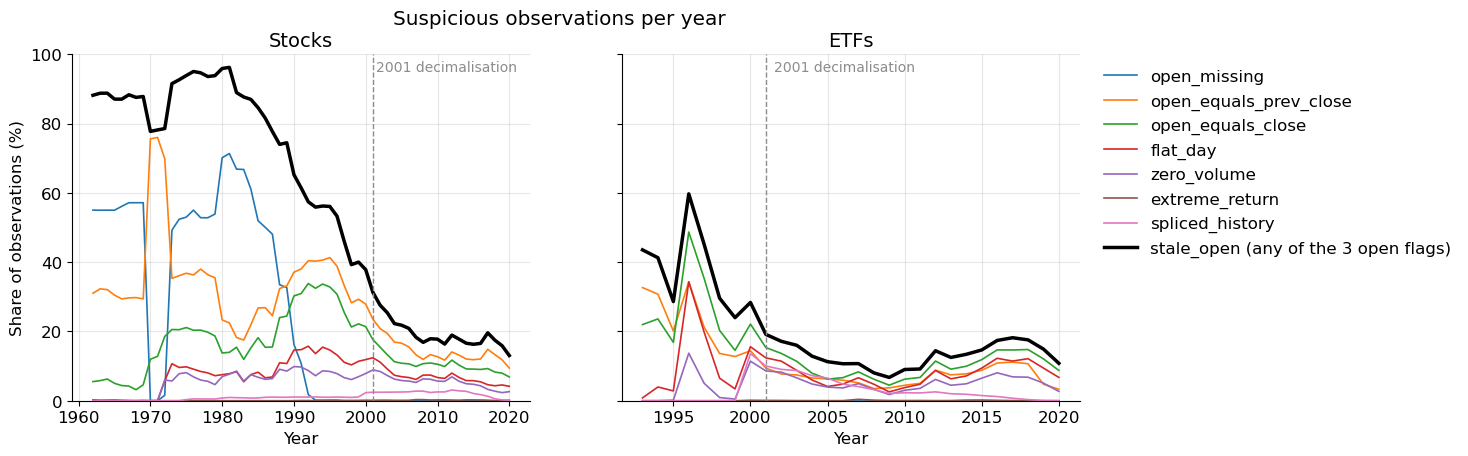

In [51]:
prices = flag_suspicious(add_dollar_volume(add_price_night(add_returns(prices))))
share = suspicious_share_by_year(prices)
fig = plot_suspicious_share(share)

Share of flagged stock observations in selected years (the `spliced_history` column is the one cited below):

In [52]:
# Selected years bracket early data problems, decimalisation and the last full year; x100 gives %.
(100 * share.loc["stock"].loc[[1980, 1990, 1997, 2000, 2001, 2005, 2019]]).round(1)

,open_missing,open_equals_prev_close,open_equals_close,flat_day,zero_volume,extreme_return,spliced_history,stale_open
year,,,,,,,,
1980,70.1,23.3,13.8,7.5,7.0,0.0,0.8,95.9
1990,16.2,37.1,30.2,14.6,9.9,0.0,1.1,65.2
1997,0.0,33.3,25.5,11.1,6.7,0.0,1.0,46.0
2000,0.0,27.9,21.4,11.9,7.9,0.1,2.3,37.8
2001,0.0,23.5,17.6,12.4,8.9,0.1,2.4,31.3
2005,0.0,16.6,10.8,6.9,5.8,0.1,2.5,21.8
2019,0.0,11.8,8.0,4.5,2.3,0.0,0.2,15.9


Missing opens near 1998, in counts. The 88 rows of 1997 round to 0.0 % in the table above:

In [53]:
# Inspect the years around 1998, the chosen start of the study sample.
flag_count_by_year(prices, "open_missing").loc[1995:1999]

year
1995    647
1996    709
1997     88
1998      0
1999      0
Name: open_missing, dtype: int64

Tickers whose history is cut by `spliced_history`, with three hand-checked examples:

In [54]:
print(f"{prices.loc[prices.spliced_history, 'ticker'].nunique()} tickers, {prices.spliced_history.sum():,} rows")
# Hand-checked cases: FTAI/BILL joined histories and the ambiguous NVR recapitalisation.
splice_examples(prices, ["FTAI", "BILL", "NVR"])

323 tickers, 503,604 rows


,first date,jump date,close before,close after,flagged rows
FTAI,1996-01-03,2015-05-14,759.90,17.00,4845
BILL,2014-07-21,2019-12-12,2.88,35.50,146
NVR,1985-07-22,1993-10-01,0.38,10.25,2073


**Takeaway:** In 1980, 70.1 % of stock opens are missing and 95.9 % are stale, so those years cannot support a night-versus-day comparison. Missing opens fall to 88 rows in 1997 and to 0 from 1998. Stale opens do not vanish: 37.8 % of stock observations in 2000, 21.8 % in 2005, 15.9 % in 2019, a decline consistent with the 2001 decimalisation. Extreme returns stay at 0.1 % or below in the years shown. `spliced_history` flags 323 tickers and 503,604 rows. FTAI and BILL are another series glued on before the listing; NVR in 1993 may be a real recapitalisation, so the rule can drop a true history.

A stale open is not always an error. Share of stale stock opens (%) by quintile of the previous day's dollar volume (Q1 = least traded) and by the previous close, from 1998:

In [55]:
stale_share_by_liquidity(prices, start_year=STUDY_START_YEAR)

,Q1,Q2,Q3,Q4,Q5,price < $5,price >= $5
asset_type,,,,,,,
etf,40.8,8.8,6.7,6.3,5.0,68.1,13.5
stock,49.4,21.1,15.3,10.4,7.2,38.6,17.5


**Takeaway:** Stale opens are concentrated among illiquid names: 49.4 % of stock days in Q1, against 7.2 % in Q5; 38.6 % when the previous close is below \$5, against 17.5 % above. Even the most traded quintile still has 7.2 % stale opens, so some equalities are genuine prices. Removing them selects observations by their return. Whether that choice changes the night–day gap is tested in II.6.

> **Decision:** The study period starts in **1998**, the first year with no missing opens (88 remain in 1997). The main sample keeps a row only if:
> - **the ticker was liquid the day before:** the previous close is at least \$5, and the previous day's dollar volume (close × shares traded) is not in the bottom 20 % of the tickers that traded that day. Both are known at the previous close, before the night starts, so this screen uses no later information;
> - **the row has no data error:** the open is not missing, neither half of the day moves by more than 50 %, and the row is not part of a spliced history. These last two checks look at the whole series: they correct the data, they are not rules a trader could apply in real time.
>
> II.6 compares this filter with the stale-open filter and with a light filter that only removes data errors.

In [56]:
filter_summary(prices, start_year=STUDY_START_YEAR)

,rows kept,% of all rows,% of study period
liquidity,17266626,61.4,74.1
stale,18639588,66.3,80.0
light,22826437,81.1,98.0


Some securities have a US "night" that is not really a night, so they leave the main sample:
- **foreign ETFs** hold shares listed abroad, so their US night is partly the trading day of their home market. They are found from the fund name: a country, a region, "ex-US", "world", "global" or a currency (full list in `src/data/metadata.py`);
- **foreign stocks** are companies that file the forms of foreign issuers (6-K, 20-F or 40-F) with the SEC, the US market regulator. Stocks that we could not link to the SEC stay in the sample;
- **leveraged and inverse ETFs** return a fixed multiple of an index, so their returns are mechanical.

In [57]:
meta = tag_special_etfs(meta)
etf_exclusion_counts(meta)

,ETFs
all ETFs,2165
foreign,635
leveraged / inverse,191
both,37
kept in the main analysis,1376


Stock tickers, ETF tickers and rows left after each step. The last line is the study sample `study`, used by every later part:

In [79]:
study = study_sample(prices, meta)
unlinked = unlinked_stocks(study)
print(f"Stocks not linked to the SEC: {study.loc[unlinked, 'ticker'].nunique():,} tickers, {unlinked.mean():.1%} of the study rows")
exclusion_waterfall(prices, meta)

Stocks not linked to the SEC: 561 tickers, 6.2% of the study rows


,stock tickers,ETF tickers,rows,% of all rows
all rows,5884,2165,28132072,100.0
from 1998,5884,2165,23294146,82.8
liquidity and quality filter,5869,2165,17266626,61.4
without foreign and leveraged ETFs,5869,1376,16093203,57.2
without foreign stocks,5103,1376,14568671,51.8


**Takeaway:** The study sample keeps 14.6 million rows, 51.8 % of the file, with 5,103 stocks and 1,376 ETFs. Starting in 1998 removes 17.2 % of the rows, and after the liquidity and quality filter 61.4 % remain. The exclusions then remove 789 ETFs (635 foreign and 191 leveraged or inverse, 37 being both) and 766 foreign stocks, 2.7 million rows in total. 561 stocks, 6.2 % of the study rows, could not be linked to the SEC and stay in the sample; II.6 checks that they do not drive the result.

## I.7 Descriptive statistics

Missing values per column in the cleaned table (`prices`, all years):

In [59]:
missing_values(prices, ["open", "close", "open_adj", "high_adj", "low_adj", "close_adj", "volume", "r_night", "r_day"])

,missing,share (%)
open,1176088,4.18
close,0,0.00
open_adj,1176088,4.18
high_adj,153,0.00
low_adj,153,0.00
close_adj,0,0.00
volume,0,0.00
r_night,1210137,4.30
r_day,1176088,4.18


`open` is missing where the raw open was 0 (I.6), and returns are missing when the open is missing or the previous trading day is absent. `high_adj` and `low_adj` are missing where `High < Low`.

The return statistics below use the study sample (`study`). Distribution of overnight and intraday returns:

In [60]:
return_stats(study)

n  mean (%)  median (%)  std (%)  p1 (%)  p99 (%)  \
asset_type return                                                             
stock      night   12655403     0.037        0.00    1.464  -3.930    4.106   
           day     12658923     0.001        0.00    2.553  -7.292    7.553   
etf        night    1908382     0.044        0.04    0.886  -2.552    2.346   
           day      1909748    -0.026        0.00    1.124  -3.406    3.168   

                   skewness  excess kurtosis  
asset_type return                             
stock      night      0.003          100.254  
           day        0.456           21.270  
etf        night     -0.517           88.151  
           day        0.018           31.898

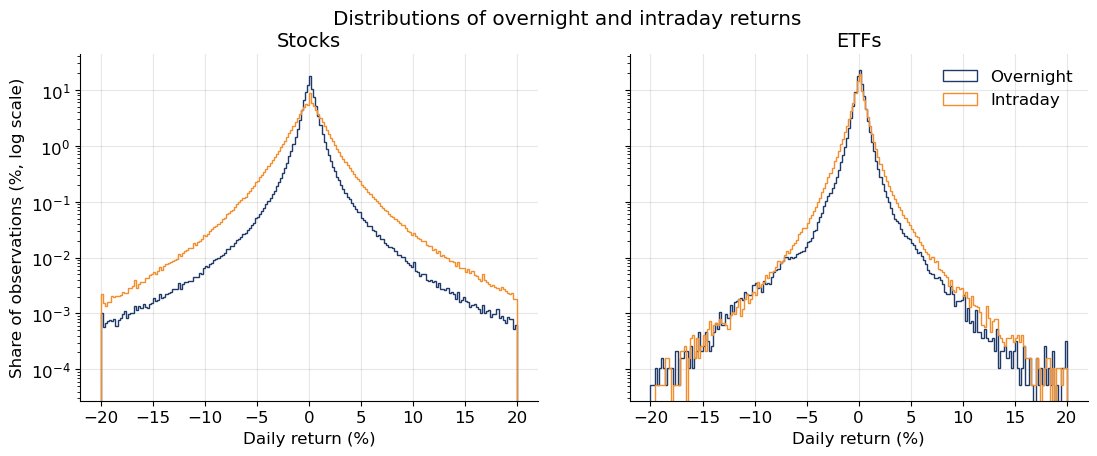

In [61]:
fig = plot_return_distributions(study)

**Takeaway:** Returns are strongly heavy-tailed: excess kurtosis ranges from 21 to 100 (0 for a normal distribution). The **mean** overnight return of stocks is 0.037 % **per day**, against 0.001 % intraday; for ETFs the means are 0.044 % overnight and −0.026 % intraday. Medians sit at 0, except the ETF overnight median (0.04 %). The trading session is more volatile than the night (stock standard deviation 2.55 % against 1.46 %) even though it lasts about 6 h 30 against 17 h 30, so per hour the difference is larger still. These pooled figures give more weight to tickers with long histories, so Part II compares night and day on daily portfolios.

Correlation between the overnight and the intraday return of the same day, on `study`. Pearson measures a linear relation and is sensitive to extreme values; Spearman uses ranks, so it is robust to heavy tails:

In [62]:
night_day_correlation(study)

,pearson,spearman
asset_type,,
stock,-0.081,-0.074
etf,-0.061,-0.029


**Takeaway:** Overnight and intraday returns are negatively correlated, for stocks (Pearson −0.08, Spearman −0.07) and less for ETFs (−0.06, −0.03): part of the overnight move tends to be reversed during the day. A noisy opening price also creates this mechanically (an open that is too high makes the night look better and the day worse).

Distribution of daily **dollar** volume (`prices`, all years: this describes the raw cleaned table, not `study`):

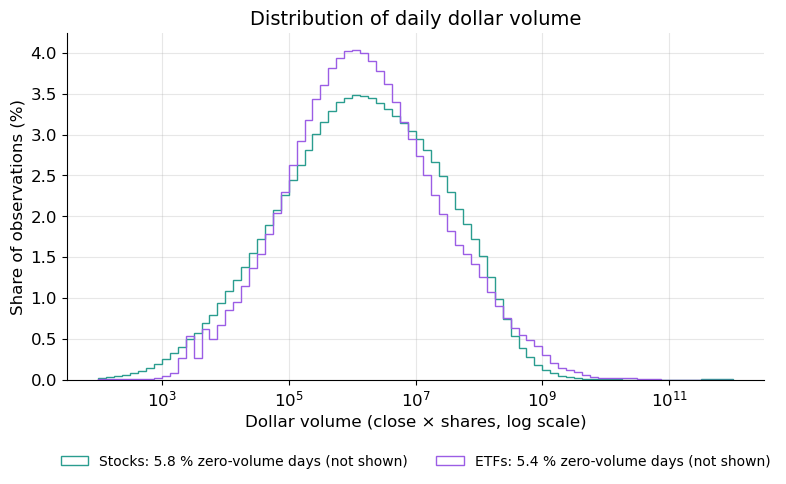

In [63]:
fig = plot_volume_distribution(prices)

In [64]:
volume_summary(prices)

,zero-volume days (%),p1 ($),median ($),p99 ($)
asset_type,,,,
stock,5.8,1250,1453500,497385426
etf,5.4,2852,1392248,1108722747


In [65]:
stale_among_zero_volume(prices)

zero-volume days           1610344.0
of which stale open (%)         92.7
dtype: float64

**Takeaway:** On traded days, stock dollar volume ranges from \$1,250 (1st percentile) to \$497 million (99th), about five orders of magnitude, hence the log scale. In dollars, the median ETF (\$1.39 million) is close to the median stock (\$1.45 million): the gap seen in share counts is mostly a difference of price per share. 5.8 % of stock days and 5.4 % of ETF days have zero volume; 92.7 % of those zero-volume days also have a stale open.

# Part II - The Crime

Part I built the study sample. Part II establishes the fact the whole project rests on: in our data, holding stocks only overnight earns more than holding them only during the trading day. This part describes the fact; the next parts ask why.

**Roadmap:** II.1 shows the crime on SPY. II.2 asks whether it holds for all stocks and ETFs. II.3 tests whether the gap could be chance. II.4 asks which stocks carry it. II.5 follows it through time. II.6 checks that it survives other reasonable choices.

> **Decision (25 November 2026, after the P2 feedback):**
> - **Main test:** a block bootstrap of the daily night − day gap (II.3). The date-clustered regression is a check.
> - **Reference for the market:** SPY. The two stock portfolios, equal-weighted and dollar-volume-weighted, are shown side by side as two views of all stocks; neither is the main one.
> - **Sample:** the study sample of Part I.
>
> At P2 the two tests disagreed on SPY: the clustered p-value was 0.073, while the bootstrap interval was above 0. We chose the bootstrap because it lets consecutive days depend on each other, which the clustered test does not. We made this choice after seeing both results, so II.6 also reports the bootstrap with shorter and longer blocks.

## II.1 Does the crime exist? (SPY)

The value of \$1 invested only in one half of the day, and the convention used to annualise:

$$V_T = \prod_{t \le T} (1 + r_t), \qquad \text{annualised mean} = 252 \times \text{mean daily return}$$

252 is the usual number of US trading days in a year. Buy-and-hold compounds both halves each day: $(1+r^{\text{night}}_t)(1+r^{\text{day}}_t)$.

Log returns split the close-to-close return exactly (lecture 05, log outcomes for heavy tails):

$$\underbrace{\log\frac{\text{close\_adj}_t}{\text{close\_adj}_{t-1}}}_{\text{total}} = \underbrace{\log(1+r^{\text{night}}_t)}_{\text{night}} + \underbrace{\log(1+r^{\text{day}}_t)}_{\text{day}}$$

Their sums tell us what share of the total return comes from the night. SPY, the largest US equity ETF, from the start of the study period:

,first date,last date,days,value of $1,annualised mean (%),share of log return (%)
overnight,1998-01-02,2020-04-01,5598,4.74,7.64,116.61
intraday,1998-01-02,2020-04-01,5598,0.80,0.29,-16.61
buy-and-hold,1998-01-02,2020-04-01,5598,3.80,7.98,100.00


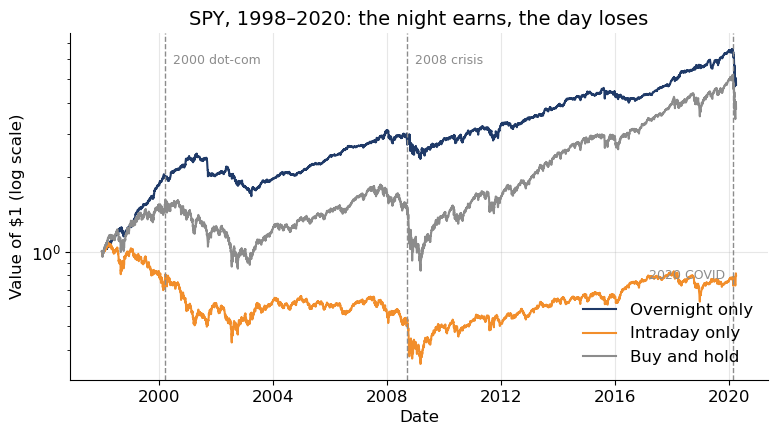

In [66]:
# SPY is the broad US equity benchmark used for the opening example.
wealth = ticker_wealth(study, "SPY")
fig = plot_wealth(wealth, f"SPY, {STUDY_START_YEAR}–2020: the night earns, the day loses")
crime_headline(study, "SPY")

**Takeaway:** \$1 invested in SPY from 2 January 1998 to 1 April 2020 became \$4.74 overnight only, \$0.80 during the trading day only, and \$3.80 buy-and-hold. The night's annualised mean return is 7.64 %, the day's 0.29 %. Because the day lost money, the night accounts for 116.6 % of the total log return. II.2 asks whether this is only SPY.

## II.2 Is it general?

SPY is one fund. To see whether the pattern holds across the market, we build daily portfolios of all the stocks, and of all the ETFs, of the study sample. A portfolio return on day $t$ combines the tickers available that day:

- **equal-weighted:** every ticker counts the same, $r^{\text{EW}}_t = \frac{1}{N_t}\sum_i r_{i,t}$;
- **dollar-volume-weighted:** a ticker counts in proportion to the value it traded, $r^{\text{DV}}_t = \sum_i w_{i,t}\, r_{i,t}$, with $w_{i,t}$ proportional to the mean of close × volume over the previous 20 trading days.

The weights use only past days. Market capitalisation is not in the dataset, so dollar volume stands in for size: it gives more weight to large, heavily traded firms, while equal weights give small firms as much room as large ones.

In [67]:
ports = study_portfolios(study)
portfolio_headlines(ports)

first date   last date  days  \
portfolio              strategy                                     
Stocks, equal-weighted overnight     1998-01-02  2020-04-01  5598   
                       intraday      1998-01-02  2020-04-01  5598   
                       buy-and-hold  1998-01-02  2020-04-01  5598   
Stocks, dollar-volume  overnight     1998-02-02  2020-04-01  5578   
                       intraday      1998-02-02  2020-04-01  5578   
                       buy-and-hold  1998-02-02  2020-04-01  5578   
ETFs, equal-weighted   overnight     1998-01-02  2020-04-01  5598   
                       intraday      1998-01-02  2020-04-01  5598   
                       buy-and-hold  1998-01-02  2020-04-01  5598   
ETFs, dollar-volume    overnight     1998-02-02  2020-04-01  5578   
                       intraday      1998-02-02  2020-04-01  5578   
                       buy-and-hold  1998-02-02  2020-04-01  5578   

                                     value of $1  annualised mean (%)  \
portfolio              strategy                                         
Stocks, equal-weighted overnight            8.03                 9.80   
                       intraday             1.20                 2.06   
                       buy-and-hold         9.66                12.07   
Stocks, dollar-volume  overnight           21.79                14.81   
                       intraday             0.27                -3.99   
                       buy-and-hold         5.79                10.87   
ETFs, equal-weighted   overnight           26.37                15.19   
                       intraday             0.14                -7.99   
                       buy-and-hold         3.65                 7.27   
ETFs, dollar-volume    overnight            8.97                10.64   
                       intraday             0.29                -3.77   
                       buy-and-hold         2.60                 6.88   

                                     share of log return (%)  
portfolio              strategy                               
Stocks, equal-weighted overnight                       91.85  
                       intraday                         8.15  
                       buy-and-hold                   100.00  
Stocks, dollar-volume  overnight                      175.43  
                       intraday                       -75.43  
                       buy-and-hold                   100.00  
ETFs, equal-weighted   overnight                      252.47  
                       intraday                      -152.47  
                       buy-and-hold                   100.00  
ETFs, dollar-volume    overnight                      229.30  
                       intraday                      -129.30  
                       buy-and-hold                   100.00

Value of \$1 in each portfolio, for stocks and then for ETFs:

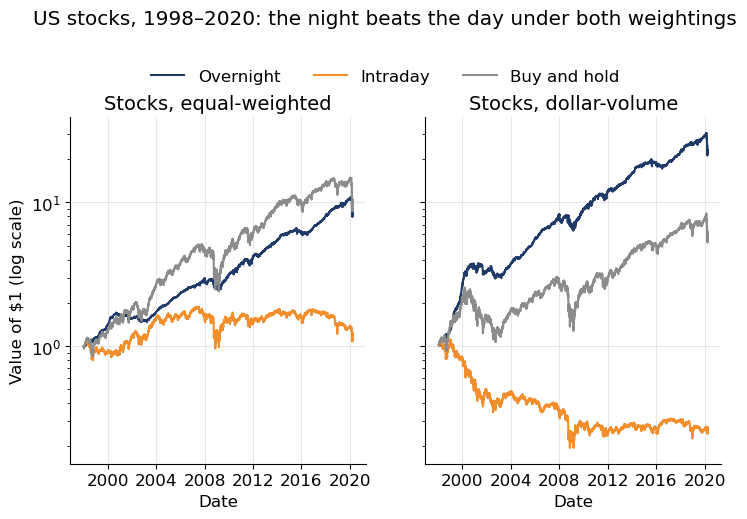

In [68]:
fig = plot_wealth_grid(
    portfolio_paths(ports, ["Stocks, equal-weighted", "Stocks, dollar-volume"]),
    f"US stocks, {STUDY_START_YEAR}–2020: the night beats the day under both weightings",
)

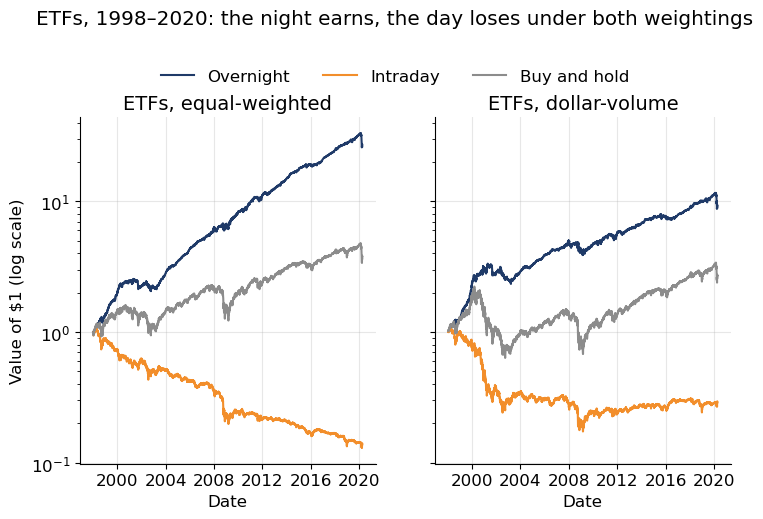

In [69]:
fig = plot_wealth_grid(
    portfolio_paths(ports, ["ETFs, equal-weighted", "ETFs, dollar-volume"]),
    f"ETFs, {STUDY_START_YEAR}–2020: the night earns, the day loses under both weightings",
)

**Takeaway:** The crime is not only SPY. \$1 in dollar-volume-weighted stocks became \$21.79 overnight and \$0.27 during the day, a day that loses 3.99 % a year. With equal weights the night still wins, \$8.03 against \$1.20, but the day no longer loses money (2.06 % a year against 9.80 % overnight). For stocks, the losing day therefore comes from the large, heavily traded firms. For ETFs, \$1 became \$26.37 overnight and \$0.14 during the day with equal weights, \$8.97 and \$0.29 with dollar-volume weights.

Portfolios average over many tickers. For each ticker with at least 252 days with both returns (about one year), the annualised gap $252 \times \left(\overline{r^{\text{night}}} - \overline{r^{\text{day}}}\right)$:

,tickers,night > day (%),median gap (%)
asset_type,,,
stock,4310,56.9,4.9
etf,946,88.2,15.9


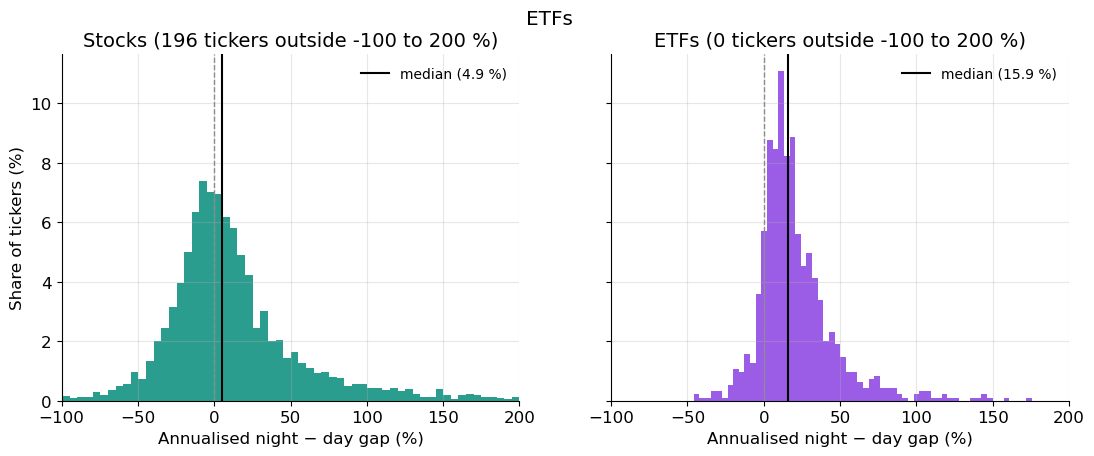

In [70]:
gaps = night_day_gap_by_ticker(study)
share = gap_share_above_zero(gaps)
ahead = share["night > day (%)"]
fig = plot_gap_histogram(gaps, f"The night beats the day for {ahead['etf']:.0f} % of ETFs but only {ahead['stock']:.0f} % of stocks")
share

**Takeaway:** The night earns more than the day for 56.9 % of the 4,310 stocks with at least 252 paired days, and for 88.2 % of the 946 ETFs. The median annualised gap is 4.9 % for stocks and 15.9 % for ETFs. The pattern is common, but not universal among stocks: 43.1 % have the opposite sign.

## II.3 Could the gap be chance?

Daily returns are noisy, so a positive average gap could appear by luck. Let $d_t = r^{\text{night}}_t - r^{\text{day}}_t$ be the gap of day $t$. The question is whether its mean is above 0.

The main test is a block bootstrap. We build 1,000 artificial histories by drawing, with replacement, blocks of 21 consecutive trading days (about a month) from the real series, and compute the mean gap of each history. The 2.5th and 97.5th percentiles of these means give a 95 % interval. Drawing whole blocks keeps the dependence between consecutive days, such as calm and turbulent periods. The random seed is fixed (0), so the intervals are reproducible.

As a check, following lecture 05, we stack the night and day returns and estimate

$$r_{t,s} = \alpha + \beta \cdot \mathbb{1}[s=\text{night}] + \varepsilon_{t,s}$$

where $\beta$ is the mean night − day difference. Standard errors are clustered by date: the night and the day of the same date may be correlated, but different dates are treated as independent.

In [71]:
books = make_books(study, ports)
gap_bootstrap(books)

,portfolio,first date,last date,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,SPY,1998-01-02,2020-04-01,21,1000,0.03,7.35,0.30,15.69
1,"Stocks, equal-weighted",1998-01-02,2020-04-01,21,1000,0.03,7.74,1.77,14.94
2,"Stocks, dollar-volume",1998-02-02,2020-04-01,21,1000,0.07,18.80,11.77,27.86
3,"ETFs, equal-weighted",1998-01-02,2020-04-01,21,1000,0.09,23.17,18.15,29.47
4,"ETFs, dollar-volume",1998-02-02,2020-04-01,21,1000,0.06,14.40,7.48,23.44


The regression on the same portfolios, as a check:

In [72]:
gap_regression(books)


,portfolio,first date,last date,beta daily (%),beta annualised (%),SE daily (%),CI 95% low,CI 95% high,p-value,n days
0,SPY,1998-01-02,2020-04-01,0.0292,7.3510,0.0163,-0.6877,15.3898,0.0731,5598
1,"Stocks, equal-weighted",1998-01-02,2020-04-01,0.0307,7.7424,0.0142,0.7047,14.7801,0.0311,5598
2,"Stocks, dollar-volume",1998-02-02,2020-04-01,0.0746,18.8004,0.0201,8.8605,28.7404,0.0002,5578
3,"ETFs, equal-weighted",1998-01-02,2020-04-01,0.0920,23.1729,0.0135,16.5037,29.8421,0.0000,5598
4,"ETFs, dollar-volume",1998-02-02,2020-04-01,0.0572,14.4047,0.0190,5.0198,23.7896,0.0026,5578


**Takeaway:** Under the main test, every interval excludes 0. SPY's gap is 7.35 % a year [0.30, 15.69], with a lower bound close to 0. Dollar-volume stocks are at 18.80 % [11.77, 27.86], equal-weighted stocks 7.74 % [1.77, 14.94], dollar-volume ETFs 14.40 % [7.48, 23.44] and equal-weighted ETFs 23.17 % [18.15, 29.47]. The regression agrees on the four portfolios (p ≤ 0.031). On SPY it does not separate the gap from 0 (p = 0.073, interval [−0.69, 15.39]), so the SPY result depends on the test and the portfolio results do not.

## II.4 Which securities carry the gap?

If the gap came from stale or noisy opening prices, it would sit in the least traded stocks. We split stocks into five equal-weighted portfolios by their mean dollar volume over the previous 20 days, ranked among the stocks of each day: Q1 is the least traded fifth, Q5 the most traded. Each portfolio is tested with the bootstrap of II.3.

In [73]:
gap_bootstrap(liquidity_quintiles(study, "stock"))

,portfolio,first date,last date,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,Q1,1998-02-02,2020-04-01,21,1000,0.03,7.89,3.52,13.40
1,Q2,1998-02-02,2020-04-01,21,1000,0.03,7.48,1.76,14.84
2,Q3,1998-02-02,2020-04-01,21,1000,0.02,4.68,-1.97,13.27
3,Q4,1998-02-02,2020-04-01,21,1000,0.03,6.78,-0.21,15.41
4,Q5,1998-02-02,2020-04-01,21,1000,0.04,10.30,3.28,18.89


**Takeaway:** The gap is not reserved for the least traded stocks. Q5, the most traded fifth, has the largest gap, 10.30 % [3.28, 18.89]. Q1 is at 7.89 % [3.52, 13.40] and Q2 at 7.48 % [1.76, 14.84]. Q3 (4.68 % [−1.97, 13.27]) and Q4 (6.78 % [−0.21, 15.41]) include 0. Together with II.2, the gap is largest among the most traded stocks.

The ETF gap is even larger than the stock gap (II.3). To see where it comes from, we run the same test on equal-weighted ETF portfolios by kind of fund, read from the fund name (bonds and income, volatility and commodities, equity and others), and by liquidity quintile among ETFs:

In [74]:
etf_books = {**etf_kind_books(study, etf_kinds(meta)), **{f"ETF {q}": book for q, book in liquidity_quintiles(study, "etf").items()}}
gap_bootstrap(etf_books)

,portfolio,first date,last date,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,bond / income,2000-05-30,2020-04-01,21,1000,0.04,10.69,5.48,15.76
1,equity / other,1998-01-02,2020-04-01,21,1000,0.10,24.62,18.81,31.74
2,volatility / commodity,2003-02-03,2020-04-01,21,1000,0.07,17.56,9.54,23.89
3,ETF Q1,1999-01-22,2020-04-01,21,1000,0.08,21.37,16.26,27.32
4,ETF Q2,1998-02-18,2020-04-01,21,1000,0.10,26.33,20.49,33.21
5,ETF Q3,1998-02-02,2020-04-01,21,1000,0.09,21.80,16.28,28.20
6,ETF Q4,1998-02-18,2020-04-01,21,1000,0.10,25.27,19.65,32.85
7,ETF Q5,1998-02-02,2020-04-01,21,1000,0.06,15.59,9.88,22.64


**Takeaway:** The ETF gap is not a liquidity effect: it is positive in every liquidity quintile, from 15.59 % [9.88, 22.64] in Q5 to 26.33 % [20.49, 33.21] in Q2. It is not one kind of fund either: 24.62 % [18.81, 31.74] for equity funds, 17.56 % [9.54, 23.89] for volatility and commodity funds, and still 10.69 % [5.48, 15.76] for bond funds. A bond fund that earns about 10 % a year more at night than during the day has no clear economic reason. This suggests that ETF opening prices are biased, for example because an ETF starts trading before all the securities it holds have a price. Daily data cannot test this.

## II.5 Has the gap been there all along?

For each date, the annualised mean overnight and intraday returns of the previous 756 trading days (about three years). Only past days enter each window. The table gives the share of windows in which the night is ahead.

SPY                       72.4
Stocks, dollar-volume     99.1
Stocks, equal-weighted    83.1
Name: windows with night > day (%), dtype: float64

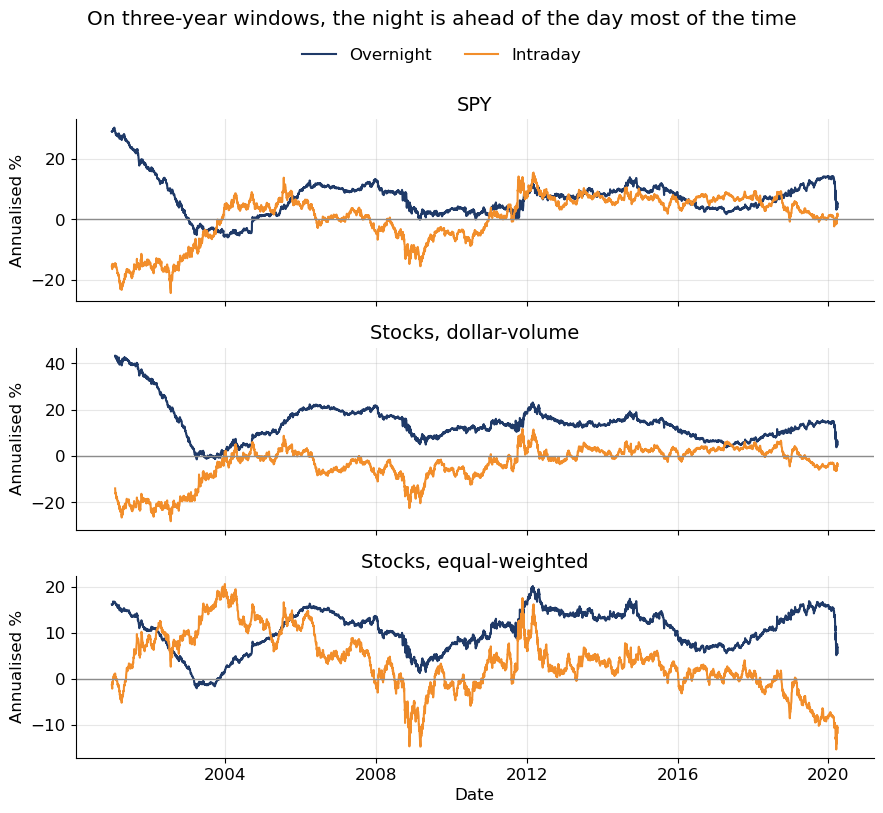

In [75]:
roll_names = ["SPY", "Stocks, dollar-volume", "Stocks, equal-weighted"]
rolled = {name: rolling_annualised(books[name], 756) for name in roll_names}
fig = plot_rolling_means(rolled, "On three-year windows, the night is ahead of the day most of the time")
night_ahead_share(rolled)

The sample ends with the COVID crash. Value of \$1 from 3 February to 1 April 2020, the last date of the data:

strategy,overnight,intraday,buy-and-hold
portfolio,,,
SPY,0.74,1.04,0.77
"Stocks, dollar-volume",0.74,1.00,0.74
"Stocks, equal-weighted",0.76,0.90,0.68


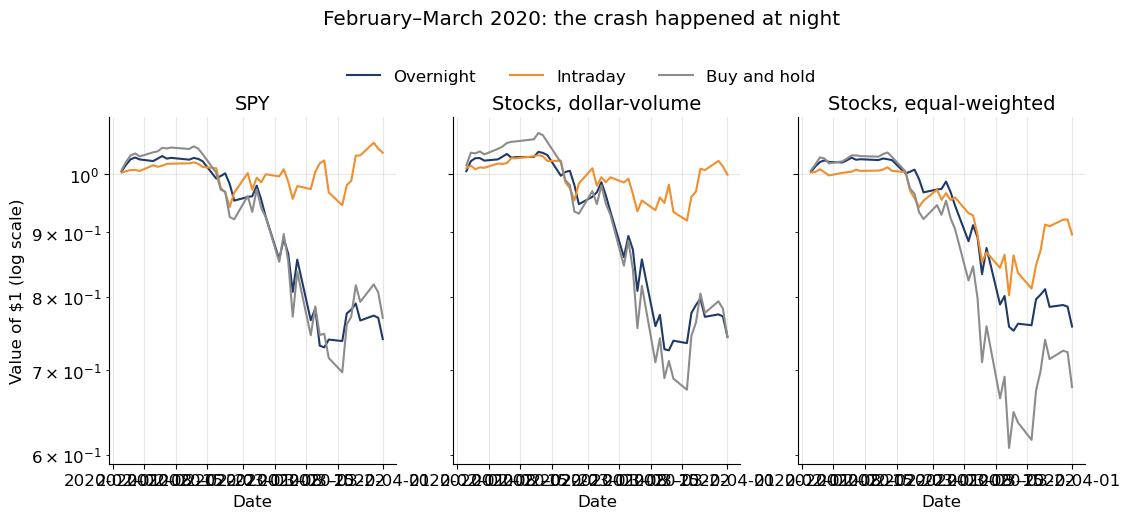

In [76]:
covid = {name: books[name].loc[books[name]["date"].ge("2020-02-01")] for name in roll_names}
fig = plot_wealth_grid(portfolio_paths(covid), "February–March 2020: the crash happened at night")
portfolio_headlines(covid)["value of $1"].unstack()

**Takeaway:** On three-year windows the night is ahead of the day in 72.4 % of SPY windows, 99.1 % of dollar-volume stock windows and 83.1 % of equal-weighted stock windows. The gap is there for most of the period, but not in every window, especially for SPY. The COVID crash happened at night: from 3 February to 1 April 2020, \$1 in SPY became \$0.74 overnight and \$1.04 during the day, and \$1 in dollar-volume stocks \$0.74 and \$1.00. Equal-weighted stocks lost in both halves (\$0.76 and \$0.90).

## II.6 Does it survive other reasonable choices?

We first change the quality filter, then the choices of the test. Section I.6 defined the main filter and two alternatives. The stale-open filter also drops opens equal to the previous close or to the same day's close: a stale open is an opening price that copies an earlier price instead of reflecting a trade, which is common for rarely traded names. The light filter only removes data errors. The filters are applied to SPY and to equal-weighted stocks, before the exclusions of Part I, so only the filter changes:

,SPY night,SPY day,SPY gap,EW stocks night,EW stocks day,EW stocks gap
liquidity,7.64,0.29,7.35,10.37,1.31,9.07
stale,7.48,-0.27,7.75,13.48,9.49,4.00
light,7.64,0.29,7.35,9.05,7.78,1.27


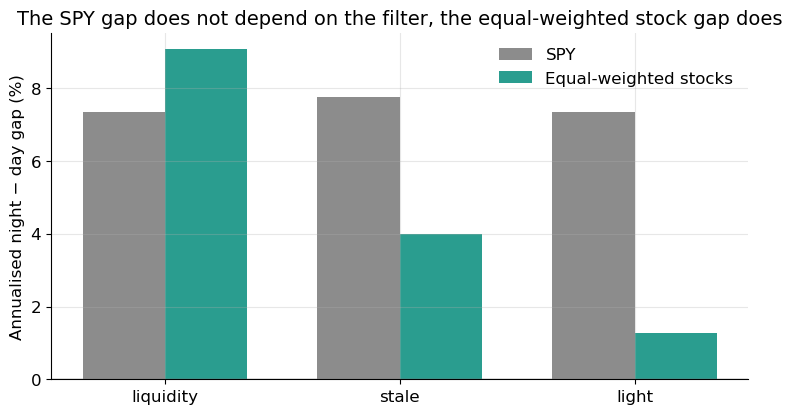

In [80]:
cmp = filter_comparison(prices, start_year=STUDY_START_YEAR, filters=FILTERS)
fig = plot_filter_comparison(cmp, "The SPY gap does not depend on the filter, the equal-weighted stock gap does")
cmp

For the test, each cell gives the annualised gap and its 95 % bootstrap interval, in %. Each column changes one choice: blocks of 5 or 63 days instead of 21; daily gaps winsorised at 1 % (a gap below the 1st or above the 99th percentile is set to that percentile), so that a few extreme days cannot drive the mean; without the two crises (the whole of 2008, and February–March 2020); the night without dividends; for stocks, only those linked to the SEC; for ETFs, without volatility and commodity funds, whose prices follow futures markets.

Dividends need a word. On an ex-dividend day the price drops by the dividend at the open, and the adjusted prices of I.5 add it back, so the whole dividend is counted in the night. It is a real gain for a shareholder, but a mechanical one. The night without dividends uses raw prices, adjusted for splits only:

$$r^{\text{night, price}}_t = \frac{\text{Open}_t}{\text{Close}_{t-1}} - 1$$

so that on an ex-dividend day the price drop counts as a loss, and $r^{\text{night}}_t - r^{\text{night, price}}_t$ is the dividend of that night.

In [81]:
gap_robustness(books, study, commodity_vol_etfs(meta), unlinked)

,main (21-day blocks),5-day blocks,63-day blocks,winsorised at 1 %,without 2008 and 2020,night without dividends,stocks linked to the SEC only,without volatility and commodity ETFs
portfolio,,,,,,,,
SPY,"7.4 [0.3, 15.7]","7.4 [-0.2, 15.5]","7.4 [1.3, 15.9]","8.8 [2.5, 16.1]","8.7 [1.4, 16.1]","5.5 [-1.6, 13.9]",–,–
"Stocks, equal-weighted","7.7 [1.8, 14.9]","7.7 [1.2, 14.8]","7.7 [2.6, 14.3]","9.2 [3.5, 15.2]","8.5 [2.4, 14.5]","4.8 [-1.2, 12.0]","7.3 [1.3, 14.7]",–
"Stocks, dollar-volume","18.8 [11.8, 27.9]","18.8 [10.7, 28.6]","18.8 [11.3, 28.1]","20.6 [14.5, 28.8]","20.4 [12.5, 28.2]","16.9 [9.9, 25.9]","18.7 [11.8, 27.9]",–
"ETFs, equal-weighted","23.2 [18.2, 29.5]","23.2 [17.3, 29.5]","23.2 [18.3, 29.6]","24.1 [19.6, 29.6]","23.2 [18.0, 28.7]","21.3 [16.3, 27.6]",–,"23.3 [18.1, 29.8]"
"ETFs, dollar-volume","14.4 [7.5, 23.4]","14.4 [6.7, 23.8]","14.4 [7.1, 24.0]","16.1 [10.1, 23.8]","15.6 [7.6, 23.4]","12.8 [6.0, 21.7]",–,"14.3 [7.3, 23.4]"


**Takeaway:** The filter matters for equal-weighted stocks, not for SPY. SPY's gap stays at 7.35 % with the liquidity and light filters and 7.75 % with the stale-open filter. The equal-weighted stock gap falls from 9.07 % with the liquidity filter to 4.00 % with the stale-open filter and 1.27 % with the light filter, because the day return jumps to 7.78 % a year once illiquid names are kept, which is consistent with bid–ask bounce (see the limits below). In the second table, the block length, the crises, the stocks not linked to the SEC and the volatility and commodity ETFs change little; with 5-day blocks the SPY interval just includes 0 ([−0.2, 15.5]). Extreme days do not create the gap: winsorised at 1 %, every gap gets larger (SPY 8.8 % [2.5, 16.1]). Dividends explain part of the gap, not all of it: without them, SPY's gap falls from 7.4 % to 5.5 % and the equal-weighted stock gap from 7.7 % to 4.8 %, and both intervals now include 0. The dollar-volume stock and ETF gaps barely move and stay above 0 (16.9 %, 21.3 % and 12.8 %).

## Conclusion

**Finding:** the night beats the day for SPY and for every portfolio of the study sample. The gap is robust for the most traded stocks and for ETFs. For SPY and equal-weighted stocks it is real but fragile, and part of it is dividends.

- **The crime appears on SPY (II.1):** \$1 became \$4.74 overnight and \$0.80 during the day. The night's share of the log return is 116.6 % because the day lost money.
- **It is common (II.2):** the night wins in all four portfolios, for 56.9 % of stocks and 88.2 % of ETFs. For stocks, the day loses money only with dollar-volume weights.
- **It is not chance for the portfolios (II.3):** their gaps go from 7.74 % to 23.17 % a year and all intervals exclude 0. SPY's interval is [0.30, 15.69], but the regression gives p = 0.073.
- **It is largest among the most traded stocks (II.4):** Q5 has the largest gap, 10.30 % [3.28, 18.89]. ETFs show a gap in every kind of fund and every liquidity quintile, even bond funds (10.69 %).
- **It lasts (II.5):** the night is ahead in 99.1 % of three-year windows for dollar-volume stocks. The COVID crash happened at night.
- **It survives other choices, except dividends for the weakest books (II.6):** blocks, extreme days, crises and exclusions change little. Without dividends, SPY (5.5 %) and equal-weighted stocks (4.8 %) can no longer be told apart from 0; dollar-volume stocks and ETFs can.

These results come with several limits. Only securities still listed in 2020 are in the data (survivorship bias, I.3). Firms delisted before 2020, often after bad news, are missing, so the sample likely lacks some of the worst nights and the gap may be overstated. Opening prices remain noisy for rarely traded names. There is no market capitalisation, only dollar-volume weights. Equal-weighted portfolios of rarely traded names are inflated by bid–ask bounce: a price that alternates between the buying and the selling quote looks like a return. Foreign ETFs are found from their names, which can miss a few funds, and stocks that we could not link to the SEC stay in the sample. The ETF gap, found even in bond funds, may partly come from how ETF opening prices are recorded, which daily data cannot check. The checks for extreme returns and spliced histories use the whole series: they correct the data, but a trader could not apply them in real time.

**Who is guilty?** II.2 and II.4 show that among stocks the gap is largest for the most traded names, which tend to attract the most news and attention. Part III asks whether longer nights pay more (risk). Part IV asks whether news lands after the close. Part V asks whether a crowd of attention produces an overnight gain and an intraday hangover. Part VI uses mistaken tickers as a natural experiment. The verdict comes last.

# Part III - The Risk Suspect (preliminary results)

Part II established the crime. We now question the first suspect: **risk**. Holding a security overnight exposes investors to news they cannot trade on until the next open. If that risk is compensated, and it grows with the length of the closure, longer closures should earn more. Two hypotheses make different predictions:

- **Per hour (calendar time):** the overnight return accrues with the hours elapsed. A weekend of about 66 hours should earn about 3.7 times a weekday night of 17.5 hours.
- **Per closure:** the overnight return is a fixed amount per closure, whatever its length.

**Roadmap:** III.1 measures the length of each night. III.2 compares mean returns across closure types. III.3 regresses returns on hours to test both hypotheses. III.4 checks whether the result depends on our choices and on including exceptional closures.

We use the four portfolios from Part II (stocks and ETFs, each equal-weighted and dollar-volume-weighted) under the common liquidity filter and the same ETF exclusions, from 2 January 1998 to 1 April 2020. This tests one prediction of a risk explanation; risk itself is not measured here.

The main analysis excludes five exceptional market closures, such as the shutdown after 11 September 2001, to focus on the regular trading calendar. Only shutdowns are excluded: a passive strategy that buys at the close and sells at the next open is not designed for such disruptions. Ordinary sessions during long crises, such as 2008 and COVID-19, remain in the sample.

## III.1 How long is a night?

A night runs from the **previous market session's close** to the current open. We use the **New York Stock Exchange (NYSE) calendar** provided by the open-source [pandas_market_calendars](https://pandas-market-calendars.readthedocs.io/en/latest/usage.html) library. It implements historical trading rules, including trading dates, opening and closing times, holidays, early closes and exceptional shutdowns.

The schedule follows **New York time**, including historical daylight-saving rules, and returns opening and closing timestamps in **UTC** ([timezone handling](https://pandas-market-calendars.readthedocs.io/en/latest/pandas_market_calendars.html)). Subtracting these timestamps gives actual elapsed hours: a weekend spanning the spring clock change is one hour shorter, and one spanning the autumn change is one hour longer. We also flag these transitions and early closes.

Consecutive dates are weekday nights; Friday–Monday is a weekend; Thursday–Monday or Friday–Tuesday is a long weekend. Midweek holidays are separate. **Exceptional closures** cover shutdowns outside the regular holiday schedule, such as those following September 2001 or Hurricane Sandy.

In [ ]:
from src.features.calendar import study_night_calendar
from src.analysis.risk import (
    risk_samples, risk_type_analysis, duration_analysis, risk_filter_comparison,
)
from src.visualization.plots import plot_risk_by_night_type, plot_duration_predictions
from src.visualization.risk_tables import (
    calendar_table, contrast_table,
    robustness_table,
)

night_calendar = study_night_calendar(prices, start_year=STUDY_START_YEAR)
calendar_table(night_calendar)

,nights,mean hours
night_type,,
Weekday,4383,17.50
Midweek holiday,53,42.58
Weekend,1013,65.57
Long weekend,144,89.62
Exceptional closure,5,103.91


**Takeaway:** A weekend closure lasts about 66 hours, 3.7 times a 17.5-hour weekday night, so the two hypotheses predict very different weekend returns. Early closes and clock changes also shift durations: a fixed number of hours for every Monday would miss these differences. The excluded observations are the returns into the reopening sessions of **17 September 2001, 14 June 2004, 3 January 2007, 31 October 2012 and 6 December 2018**. III.4 checks the effect of including them.

## III.2 Do certain closure types yield higher returns?

We compare mean overnight returns across closure types. Each point plots a type's mean return against its mean duration, in basis points per night (1 bp = 0.01 %), with the portfolio weights of II.2.

**Sample size and uncertainty:** Each portfolio contributes about 5,600 nights, excluding the five exceptional closures, for stocks and ETFs alike. Individual categories, however, contain only about **1,010 weekends, 143 long weekends and 52 midweek holidays**. We use every available night to calculate the means, but the differences between them can still reflect sampling variation.

**Block bootstrap:** As in II.4, we draw 1,000 samples of blocks of 21 consecutive market sessions (about one trading month), recalculate the means and their differences, and use the 2.5th and 97.5th percentiles as [95 % confidence limits](https://bashtage.github.io/arch/bootstrap/confidence-intervals.html#percentile-percentile). Missing and excluded returns keep their positions in the blocks but do not enter the calculations. The regression of III.3 uses the same method, and shorter and longer blocks are checked in III.4.

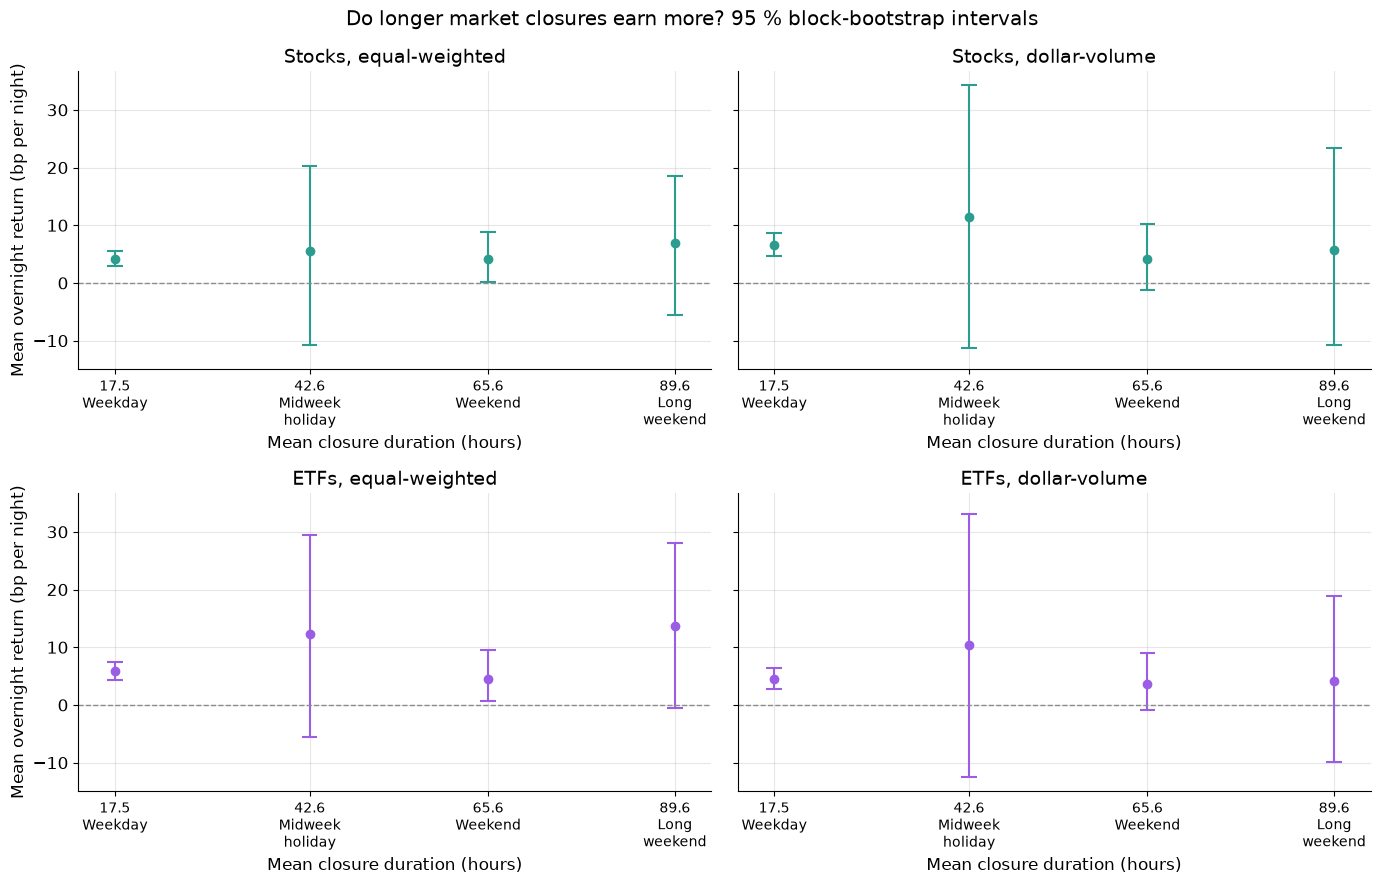

In [ ]:
risk = risk_samples(study, night_calendar)
risk_summaries, risk_contrasts = risk_type_analysis(risk)
fig = plot_risk_by_night_type(risk_summaries)

**Takeaway:** Mean returns do not rise steadily with duration in any of the four portfolios. Midweek holidays have higher sample means than weekday nights and normal weekends in all four portfolios, and the highest means in both dollar-volume-weighted portfolios. However, these estimates rely on only **52–53 nights per portfolio** and have wide confidence intervals; their differences from weekday nights remain statistically indistinguishable from zero.

To test these differences, we compare each routine closure type with weekday nights. For each bootstrap draw, we calculate the difference in means and use the resulting distribution to construct a 95 % confidence interval. Differences are in basis points per night, without multiple-comparison correction.

In [ ]:
contrast_table(risk_contrasts)

,portfolio,contrast,gap (bp),95% CI
0,"Stocks, equal-weighted",Weekend - Weekday,0.09,"[-4.02, 4.99]"
1,"Stocks, equal-weighted",Long weekend - Weekday,2.91,"[-9.5, 14.49]"
2,"Stocks, equal-weighted",Midweek holiday - Weekday,1.42,"[-14.61, 16.39]"
3,"Stocks, dollar-volume",Weekend - Weekday,-2.43,"[-7.87, 4.38]"
4,"Stocks, dollar-volume",Long weekend - Weekday,-0.90,"[-17.71, 17.06]"
5,"Stocks, dollar-volume",Midweek holiday - Weekday,4.83,"[-17.7, 28.7]"
6,"ETFs, equal-weighted",Weekend - Weekday,-1.38,"[-5.34, 4.01]"
7,"ETFs, equal-weighted",Long weekend - Weekday,7.87,"[-6.27, 22.23]"
8,"ETFs, equal-weighted",Midweek holiday - Weekday,6.44,"[-11.63, 23.93]"
9,"ETFs, dollar-volume",Weekend - Weekday,-0.85,"[-5.79, 5.09]"


**Takeaway:** Every routine closure contrast includes zero in all four portfolios. The weekend–weekday sample differences are small: **0.09 bp** more for equal-weighted stocks, **2.43 bp** less with dollar-volume weights, whereas under the per-hour hypothesis a weekend should earn about 3.7 times as much as a weekday night. Categories, however, mix duration with other calendar features, and some contain few nights. III.3 therefore uses the duration of each night directly.

## III.3 Per hour or per closure?

We now use each night's exact duration to ask whether staying invested longer earns more. A standard weekday closure lasts **17.5 hours**; we use it as the reference:

$$r^{\text{night}}_t = \mu + \beta(h_t - 17.5) + \varepsilon_t$$

Returns are in basis points and $h_t$ is the closure duration in hours. **$\mu$ is the predicted return for a 17.5-hour night**, while **$\beta$ is the additional return per extra hour**. A standard 65.5-hour weekend adds 48 hours, so its predicted return is $\mu + 48\beta$.

The two hypotheses imply:

- **Per hour:** returns are proportional to total closure duration, so $E[r^{\text{night}}_t] = (\mu/17.5)h_t$ and $\beta = \mu/17.5$. This adapts the calendar-time hypothesis of French (1980) to close-to-open returns.
- **Per closure:** extra hours earn no additional return, so $\beta = 0$ and the expected return is $\mu$ for every closure.

**Uncertainty in the regression:** We resample duration-return pairs in blocks of 21 consecutive market sessions and refit the regression 1,000 times, as in III.2. The central 95 % of the resulting estimates gives intervals for $\mu$, $\beta$ and the fitted mean at each duration. The reported coefficients use the full observed sample.

For the **per-hour hypothesis**, we calculate $\mu - 17.5\beta$ in each resample: its interval should contain zero for strict proportionality to remain compatible with the data. For the **per-closure hypothesis**, we check whether the interval for $\beta$ contains zero. These intervals describe sampling uncertainty within the observed history; they do not account for arbitrary future regime changes.

The figure shows the **predicted mean return** and its **pointwise 95 % bootstrap confidence interval**, with observed category means as dots. Individual nightly returns vary much more widely than this band. The horizontal axis shows actual closure duration: **at 17.5 hours, the fitted line equals $\mu$**.

Each panel reports $\beta$ (bp/hour), then $\mu$ at 17.5 hours (bp/night), with their 95 % intervals. A positive $\mu$ indicates a positive fitted return for the reference night; it does not by itself distinguish the two hypotheses.

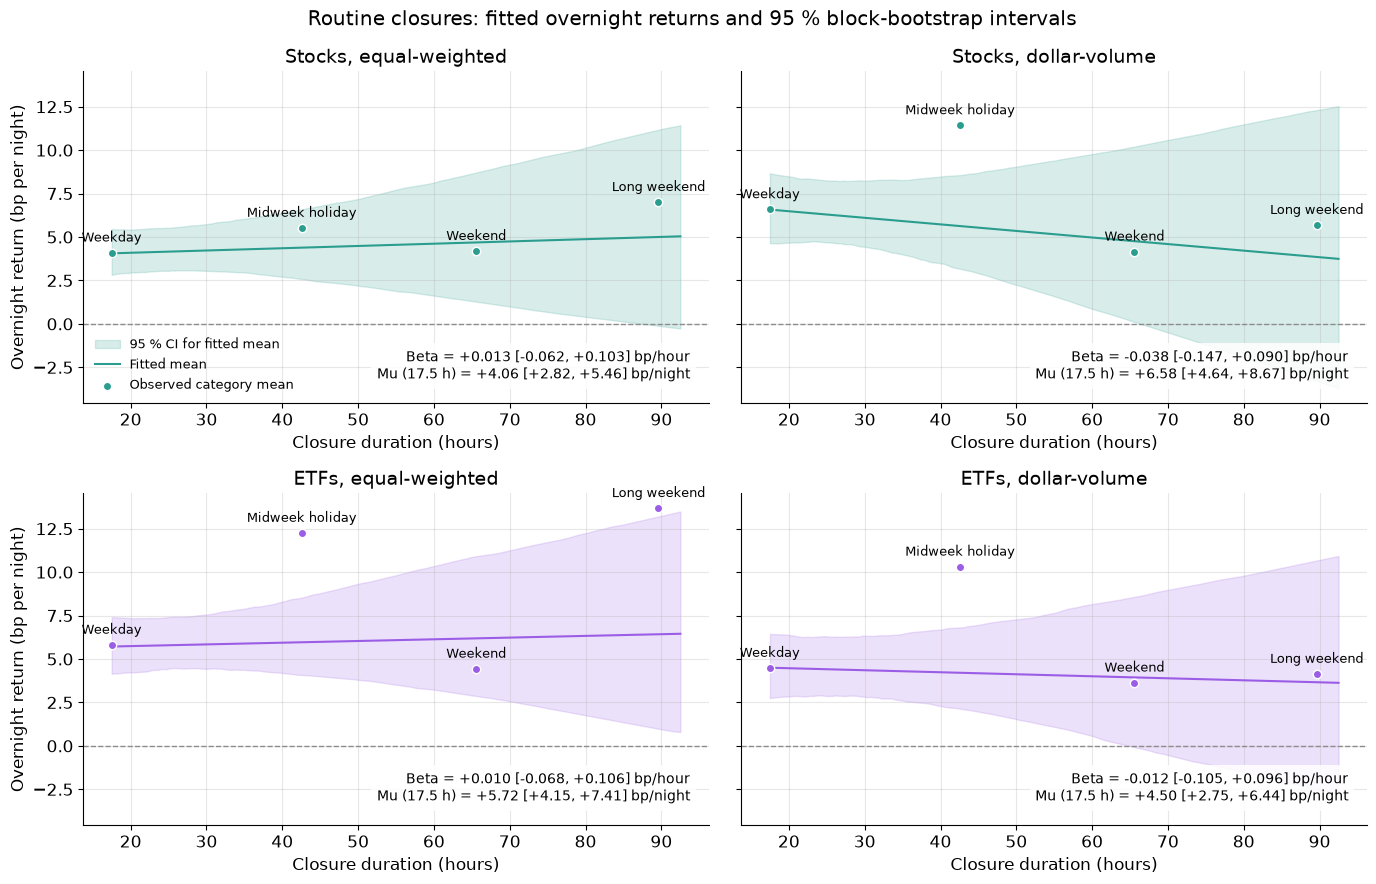

In [ ]:
risk_results, risk_predictions = duration_analysis(risk)
fig = plot_duration_predictions(risk_predictions, risk_summaries, risk_results)

**Takeaway:** The equal-weighted slopes are slightly positive and the dollar-volume-weighted slopes are negative, and all four slope intervals include zero: no statistically significant linear relationship with duration is detected. This is consistent with the hypothesis of a fixed return per closure, but does not establish a constant return. Weekday nights and weekends make up most observations; holiday closures are much less frequent.

The fitted return for a **17.5-hour closure** ranges from **4.1 to 6.6 bp per night** across portfolios. The 95 % bootstrap intervals for $\mu - 17.5\beta$ all exclude zero, providing evidence against strict proportionality to elapsed hours within the linear model.

## III.4 How robust is the result?

We vary one choice at a time in the full-period regression of III.3. The baseline uses **routine closures, simple returns, the liquidity filter and 21-session bootstrap blocks**, with 1,000 resamples.

- **5- and 63-session blocks:** check sensitivity to the length of dependence preserved in each block. The coefficients stay fixed; the confidence intervals change.
- **Include exceptional closures:** add back the five unusual shutdowns to check how much they influence the slope.
- **Alternative quality filters:** check whether the result depends on which securities and observations enter the portfolios, using Part I's stale-open and light filters.

Each entry reports **β [95 % bootstrap CI]**, in bp per extra hour. The all-night check adds five observations to each portfolio. Every other variant excludes them, including the alternative quality filters, which change portfolio composition.

In [1]:
risk_filters = risk_filter_comparison(prices, night_calendar, start_year=STUDY_START_YEAR, meta=meta)
robustness_table(risk_results, risk_filters)

portfolio,"Stocks, equal-weighted","Stocks, dollar-volume","ETFs, equal-weighted","ETFs, dollar-volume"
specification,,,,
"Main, 21-session blocks","0.013 [-0.062, 0.103]","-0.038 [-0.147, 0.09]","0.01 [-0.068, 0.106]","-0.012 [-0.105, 0.096]"
5-session blocks,"0.013 [-0.075, 0.096]","-0.038 [-0.153, 0.078]","0.01 [-0.084, 0.105]","-0.012 [-0.11, 0.088]"
63-session blocks,"0.013 [-0.061, 0.112]","-0.038 [-0.141, 0.097]","0.01 [-0.076, 0.113]","-0.012 [-0.105, 0.105]"
Include exceptional full-day closures,"-0.004 [-0.086, 0.086]","-0.067 [-0.188, 0.062]","-0.018 [-0.113, 0.088]","-0.053 [-0.178, 0.07]"
Stale-open filter,"0.03 [-0.044, 0.121]","-0.032 [-0.146, 0.103]","0.015 [-0.064, 0.113]","-0.011 [-0.105, 0.096]"
Light filter,"0.013 [-0.054, 0.093]","-0.036 [-0.146, 0.092]","0.013 [-0.062, 0.105]","-0.012 [-0.106, 0.096]"


**Takeaway:** No specification detects a statistically significant slope: every interval includes zero. Including the exceptional closures lowers all four slopes and turns both equal-weighted estimates negative; the other choices move the estimates less.

The five excluded closures are few and atypical: they last about 104 hours on average and lost 85–179 bp per night across portfolios. Their position at the far end of the duration range gives them strong influence on the slope; their returns may reflect the events that caused the shutdowns rather than elapsed time.

## Conclusion

**Preliminary finding:** no statistically detectable increase in returns with closure duration. Risk is not ruled out yet: P3 still has to test it directly, through volatility and large losses.

- **By closure type (III.2):** every closure contrast with weekday nights includes zero. Weekend sample means are close to weekday means, although weekends last 3.7 times longer.
- **Per hour or per closure (III.3):** the intervals for $\mu - 17.5\beta$ exclude zero, providing evidence against strict proportionality to hours. The intervals for $\beta$ include zero, leaving the results consistent with a premium per closure without establishing a constant return.
- **Robustness (III.4):** no statistically significant slope is detected with different bootstrap block lengths and quality filters. Including the five exceptional closures lowers all four slopes without changing this conclusion.

## Next steps for P3

1. Does the overnight premium compensate for higher risk?

   Compare volatility and large losses between overnight and intraday returns, then across closure types. Examine whether higher average returns accompany higher risk. This directly tests the risk explanation rather than assuming that longer closures are riskier.

2. Does duration matter, or does the calendar?

   Compare weekday nights of the same duration, such as Monday–Tuesday and Thursday–Friday, then examine nights around scheduled holidays. This identifies whether the overnight premium is concentrated on particular calendar dates, beyond the length of the closure.

3. Does the aggregate result hide differences between securities?

   Form portfolios ranked by their estimated sensitivity to closure duration, using only past observations. Test whether portfolios with higher historical β also have higher β in subsequent years, and examine their risk characteristics. This checks whether a stable duration effect exists for some securities despite being absent from the broad portfolios.

# Part IV - The News Suspect (preliminary results)

Part III did not find that longer nights earn more. The second suspect is news: firms often publish earnings and other important information after the close. If most news arrives at night, the overnight return could simply be the reward for news, and the gap should disappear on days without news.

We measure firm news with SEC 8-K filings. A listed US firm must file an 8-K within four business days of any important event, and EDGAR records the time of each filing. Item 2.02 marks earnings announcements.

**Roadmap:** IV.1 links tickers to SEC filings. IV.2 shows when 8-Ks are filed, and IV.3 checks that the night/day timing is right. IV.4 tests the gap without news, IV.5 measures what a news night does to a stock, and IV.6 turns to macroeconomic news.

## IV.1 Linking tickers to SEC filings

`scripts/collect_news.py` links each stock to its SEC identifier (CIK) and downloads its 8-Ks. The result is saved in `external/edgar/`, in the repository; to download it again, the SEC asks for a name and an email (`SEC_USER_AGENT="Your Name your.email@epfl.ch" python -m scripts.collect_news`, about 20 minutes). The matching has three problems:

- The SEC ticker file only has today's tickers, so firms acquired or renamed after 2020 are missing. We also match them by name with all EDGAR names (`match = name`).
- A ticker can be reused by another firm, so matches whose names differ too much are rejected (`name_mismatch`).
- Foreign firms file 6-Ks instead of 8-Ks, so they are excluded (`foreign_filer`), as are firms with no 8-K at all (`no_8k`).

Only `verified` tickers are used. Tickers and share of the stock rows in each category:

In [48]:
from src.data.edgar import load_filings, verify_identity, EDGAR_DIR
from src.analysis.news import (
    session_windows, assign_sessions, filing_time_share_by_year, filing_time_profile, timing_summary,
    coverage_table, build_news_panel, news_portfolios, news_paths, news_decomposition,
    quiet_gap_tests, timing_validation, news_regression, gap_by_issuer_group,
)
from src.visualization.news import plot_filing_times, plot_news_wealth, plot_gap_tests
import pandas as pd

stocks = study[study["asset_type"] == "stock"]
identity = verify_identity(pd.read_parquet(EDGAR_DIR / "mapping.parquet"), pd.read_parquet(EDGAR_DIR / "issuers.parquet"))
coverage_table(identity, stocks)

,tickers,share of tickers (%),share of rows (%)
status,,,
verified,4197,71.5,75.9
unmatched,561,9.6,6.4
name_mismatch,122,2.1,2.0
foreign_filer,717,12.2,10.0
no_8k,272,4.6,5.8


**Which stocks carry the crime?** Night − day gap of equal-weighted portfolios by kind of firm, 1998–2020 (Part II regression, standard errors clustered by date):

In [50]:
gap_by_issuer_group(stocks, identity)

,tickers,stock-days,gap annualised (%),CI low,CI high,p-value
"US filer, same ticker today",2650,7951275,3.459,-3.971,10.890,0.362
"US filer, delisted or renamed since 2020",1520,2810375,18.286,10.750,25.823,0.000
foreign filer (6-K / 20-F),701,1414310,20.926,13.386,28.467,0.000
not linked to EDGAR,946,2006324,10.536,5.356,15.715,0.000


**Takeaway:** The gap is 3.5 % a year (p = 0.36) for US firms still trading under the same ticker, but **18.3 %** for US firms delisted or renamed since 2020 and **20.9 %** for foreign firms (both p < 0.001). Without the name matching, the test would only see the first group. Foreign firms stay out of the test: their US night falls during their home market's trading hours.

## IV.2 When are 8-Ks filed?

EDGAR gives the acceptance time in UTC, which we convert to New York time. In the first years it only kept the date, and the time then reads exactly midnight. Number of 8-Ks and share with a recorded time, per year:

In [51]:
filings = load_filings()
# Match the 1998-2020 price-sample years when checking filing-time coverage.
filing_time_share_by_year(filings).loc[1998:2020].T

year,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
filings,3097.0,3203.0,3705.0,5022.0,7513.0,13589.0,19324.0,26513.0,27144.0,28065.0,...,30453.0,32295.0,33834.0,36629.0,39053.0,40265.0,42324.0,44062.0,46374.0,18168.0
share_time_known (%),0.1,0.0,0.0,0.1,73.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


**Takeaway:** Almost no 8-K has a time before 2002 (0.1 %), and all of them have one from 2003, so the night/day split starts in 2003. The quiet-day test only needs dates and covers 1998–2020. The number of 8-Ks doubles after August 2004, when the SEC added new events to report.

A filing accepted between the close of session $t-1$ and the open of $t$ is in the night of $t$; one accepted between the open and the close of $t$ is in the day of $t$. The NYSE calendar of Part III handles weekends, holidays and early closes. Time of the 8-Ks, from 2003:

,night,day,unknown,n
all 8-Ks,73.9,26.1,0.0,557104
earnings (item 2.02),80.2,19.8,0.0,169236
other 8-Ks,71.2,28.8,0.0,387868


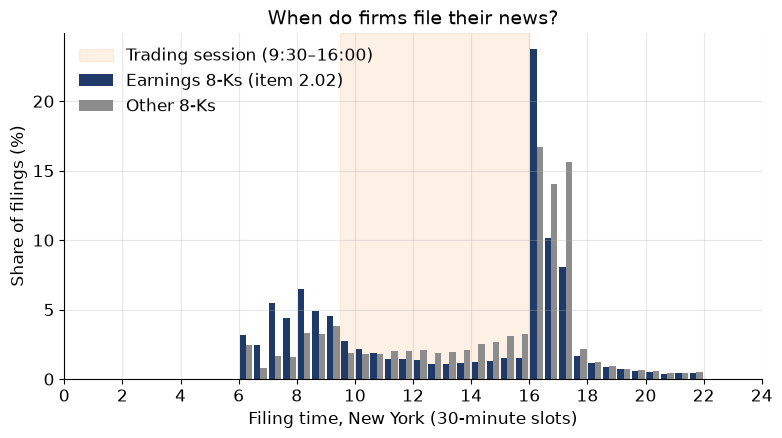

In [52]:
windows = session_windows(f"{STUDY_START_YEAR}-01-01", str(study["date"].max().date()))
assigned = assign_sessions(filings, windows)
fig = plot_filing_times(filing_time_profile(assigned))
timing_summary(assigned)

**Takeaway:** **73.9 %** of 8-Ks and **80.2 %** of earnings 8-Ks are filed outside trading hours, mostly just after the close (42 % of earnings 8-Ks between 16:00 and 17:30) or before the open (31 % between 6:00 and 9:30).

## IV.3 Is the timing right?

A covered stock-day belongs to a verified firm, after its first EDGAR filing. It is **quiet** when the firm filed nothing in sessions $t-2$ to $t+2$, which also removes news that leaks before a filing.

To check the night/day split: an 8-K in the night should make the overnight move bigger, and an 8-K in the day the intraday move. Mean absolute returns from 2003, in bp (1 bp = 0.01 %):

In [53]:
panel = build_news_panel(stocks, identity, assigned, windows)
timing_validation(panel)

,|r_night| (bp),|r_day| (bp),n
no 8-K,66.400002,151.300003,8653201
night 8-K only,181.300003,243.800003,309014
day 8-K only,109.699997,201.000000,98992


**Takeaway:** A night 8-K makes the overnight move 2.7 times bigger (181 against 66 bp). Day 8-Ks also raise the overnight move (110 against 66 bp), probably because the press release often comes before the open and the 8-K later in the day. The main test therefore uses quiet days rather than the exact split.

## IV.4 Does the crime survive without news?

As in Part II, we build daily equal-weighted portfolios of covered stocks: all stock-days and quiet stock-days (1998–2020), and stock-days with an 8-K (2003–2020). Night and day returns of a portfolio come from the same stock-days.

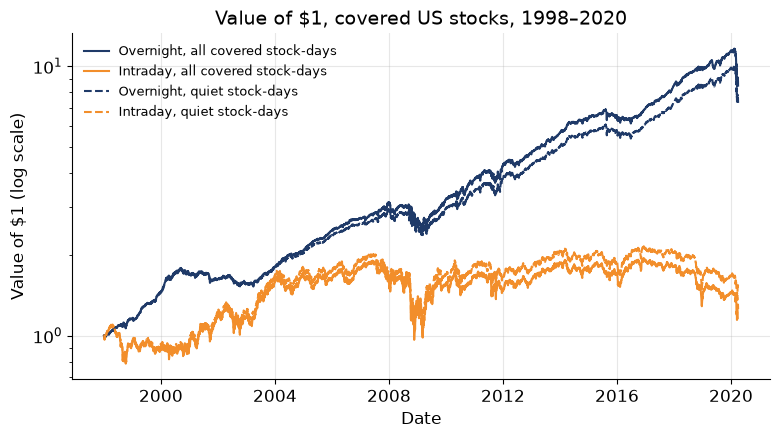

In [55]:
news_ports = news_portfolios(panel)
fig = plot_news_wealth(news_paths(news_ports), f"Value of $1, covered US stocks, {STUDY_START_YEAR}–2020")

**Takeaway:** Removing news changes little. \$1 invested only overnight grows to \$8.48 on all covered stock-days and to \$7.31 on quiet ones; intraday, it ends at \$1.27 and \$1.50.

**Statistical test:** Part II's night-indicator regression (standard errors clustered by date) and block bootstrap (21-day blocks):

,stock-days,dates,gap annualised (%),CI low (clustered),CI high (clustered),p-value,CI low (bootstrap),CI high (bootstrap)
all covered,10483138,5598,7.639,0.199,15.079,0.044,1.33,15.27
quiet (no filing within 2 sessions),8536164,5598,6.246,-1.070,13.562,0.094,-0.07,13.80
with an 8-K,412469,4342,17.370,6.929,27.810,0.001,7.23,28.03


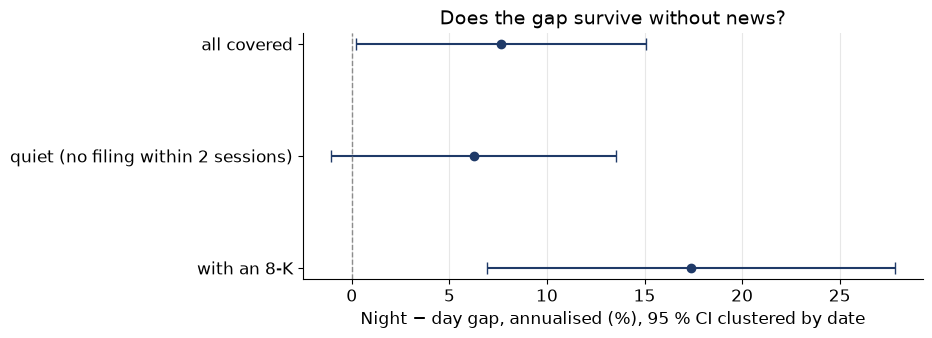

In [56]:
gap_tests = quiet_gap_tests(news_ports)
fig = plot_gap_tests(gap_tests)
gap_tests

**Takeaway:** The gap is 7.64 % a year on covered stocks (95 % CI [0.20, 15.08], p = 0.044) and **6.25 %** on quiet stock-days ([−1.07, 13.56], p = 0.094; bootstrap [−0.07, 13.80]). Removing news lowers it by about a fifth, and the interval now includes zero. Stock-days with an 8-K have a larger gap (17.4 %) but are only 4 % of the stock-days.

**Where does the overnight return come from?** Covered stock-days from 2003. If news explained the crime, nights with an 8-K would carry a much larger share of the return than of the nights:

In [57]:
news_decomposition(panel)

,observations,share of observations (%),mean (bp),share of summed return (%)
night with 8-K,313477,3.46,3.72,3.35
other night,8752209,96.54,3.85,96.65
day with 8-K,103455,1.14,1.74,NaN
other day,8962231,98.86,-0.10,NaN


**Takeaway:** Nights with an 8-K are 3.5 % of the nights and earn 3.4 % of the summed overnight return. Their mean (3.7 bp) is close to that of the other nights (3.9 bp).

## IV.5 What does a news night do to a stock?

A stock-level regression with date fixed effects, which remove the moves of the whole market:

$$r^{\text{night}}_{i,t} = a_t + b_1\, \text{earnings}_{i,t} + b_2\, \text{other 8-K}_{i,t} + \varepsilon_{i,t}$$

Standard errors are clustered by date and by stock. We use the return and the absolute return, in bp.

In [58]:
news_regression(panel)

coef (bp)   CI low  CI high  p-value  observations
outcome   regressor                                                       
r_night   earnings 8-K     -1.557   -5.409    2.296    0.428       9065686
          other 8-K         1.498    0.160    2.835    0.028       9065686
|r_night| earnings 8-K    255.296  247.002  263.589    0.000       9065686
          other 8-K        38.655   36.223   41.087    0.000       9065686

**Takeaway:** An earnings 8-K raises the absolute overnight move by **255 bp**, another 8-K by 39 bp (both p < 0.001). The effect on the return itself is small: −1.6 bp for earnings (p = 0.43) and +1.5 bp for other 8-Ks (p = 0.028), for a mean overnight return of about 4 bp. News makes nights more volatile, not more profitable.

## IV.6 Macroeconomic news

The crime is also visible on SPY, where firm news averages out. The largest scheduled news is macroeconomic: the **jobs report** and the **CPI** come out at 8:30, in the night, and the **FOMC** statement on interest rates at 14:00 (14:15 before 2013), in the day. Dates come from the FRED API and the Fed website (scheduled meetings only), and are put in sessions like 8-Ks: a jobs report on Good Friday, a market holiday, is in Monday's night. The dates are saved in `external/macro/`.

In [60]:
from src.data.macro import fomc_dates, bls_release_dates
from src.analysis.macro import place_events, macro_flags, event_counts, macro_regression_table, macro_decomposition, macro_free_gap, macro_paths
from src.visualization.news import plot_macro_paths

# Collect through April 2020 to cover the final price date, 1 April.
events = pd.concat([bls_release_dates(f"{STUDY_START_YEAR}-01-01", "2020-04-30"), fomc_dates(STUDY_START_YEAR, 2020)])
placed = place_events(events, windows)
macro = macro_flags(placed, windows)
macro_ports = {"SPY": study.loc[study["ticker"] == "SPY", ["date", "r_night", "r_day"]], **ports,
               "Covered stocks, quiet": news_ports["quiet"]}
event_counts(placed, f"{STUDY_START_YEAR}-01-01", str(study["date"].max().date()))

timing,day,night
event,,
jobs report,0,267
CPI,0,267
FOMC,177,0


**Do release sessions earn more?** Overnight return regressed on jobs-report and CPI nights, intraday return on FOMC days (bp, HAC standard errors with 5 lags). The constant is the mean of the other sessions:

In [61]:
macro_regression_table(macro_ports, macro)

jobs report night        CPI night        FOMC day  \
                                      bp      p        bp      p       bp   
SPY                                9.169  0.042    -1.210  0.781   16.248   
Stocks, equal-weighted             4.044  0.244    -3.221  0.307   21.313   
Stocks, dollar-volume              9.033  0.090    -4.157  0.405   25.985   
ETFs, equal-weighted               6.516  0.109    -1.364  0.738   18.852   
ETFs, dollar-volume               11.498  0.034    -2.949  0.534   19.581   
Covered stocks, quiet              4.265  0.232    -2.918  0.356   20.458   

                              other days  
                            p         bp  
SPY                     0.039     -0.398  
Stocks, equal-weighted  0.007     -0.126  
Stocks, dollar-volume   0.012     -2.582  
ETFs, equal-weighted    0.004     -3.537  
ETFs, dollar-volume     0.055     -2.125  
Covered stocks, quiet   0.015      0.600

**Takeaway:** On FOMC days the intraday return is **16 to 26 bp** higher in all six portfolios (p ≤ 0.015 in four, 0.039 for SPY, 0.055 for dollar-volume ETFs), while other days earn about 0. Jobs-report nights earn 9 bp more on SPY (p = 0.042), but the effect is significant in only two of six portfolios. CPI nights show no effect.

Share of the summed overnight log return earned on the 9.5 % of nights with a jobs report or a CPI release:

nights  share of nights (%)  \
SPY                    release nights (8:30)     534                 9.54   
                       other nights             5064                90.46   
Stocks, equal-weighted release nights (8:30)     534                 9.54   
                       other nights             5064                90.46   
Stocks, dollar-volume  release nights (8:30)     532                 9.54   
                       other nights             5046                90.46   
ETFs, equal-weighted   release nights (8:30)     534                 9.54   
                       other nights             5064                90.46   
ETFs, dollar-volume    release nights (8:30)     532                 9.54   
                       other nights             5046                90.46   
Covered stocks, quiet  release nights (8:30)     534                 9.54   
                       other nights             5064                90.46   

                                              mean (bp)  \
SPY                    release nights (8:30)       6.63   
                       other nights                2.65   
Stocks, equal-weighted release nights (8:30)       4.49   
                       other nights                4.08   
Stocks, dollar-volume  release nights (8:30)       8.24   
                       other nights                5.80   
ETFs, equal-weighted   release nights (8:30)       8.04   
                       other nights                5.47   
ETFs, dollar-volume    release nights (8:30)       8.08   
                       other nights                3.80   
Covered stocks, quiet  release nights (8:30)       4.34   
                       other nights                3.66   

                                              share of summed log return (%)  
SPY                    release nights (8:30)                           21.87  
                       other nights                                    78.13  
Stocks, equal-weighted release nights (8:30)                           10.52  
                       other nights                                    89.48  
Stocks, dollar-volume  release nights (8:30)                           13.28  
                       other nights                                    86.72  
ETFs, equal-weighted   release nights (8:30)                           13.59  
                       other nights                                    86.41  
ETFs, dollar-volume    release nights (8:30)                           18.83  
                       other nights                                    81.17  
Covered stocks, quiet  release nights (8:30)                           11.24  
                       other nights                                    88.76

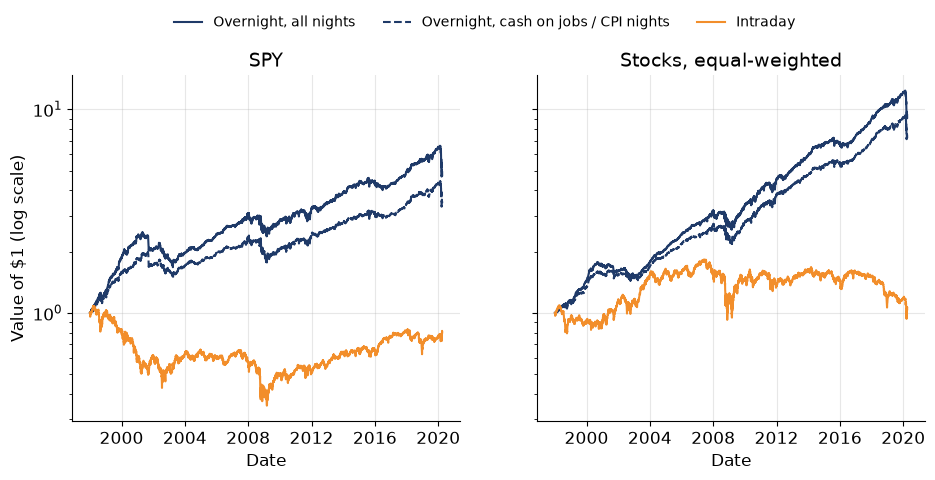

In [62]:
display(pd.concat({name: macro_decomposition(daily, macro) for name, daily in macro_ports.items()}))
fig = plot_macro_paths({name: macro_paths(macro_ports[name], macro) for name in ["SPY", "Stocks, equal-weighted"]})

**Takeaway:** These nights carry 21.9 % of SPY's overnight return (10.5 % for equal-weighted stocks). Staying in cash on them, \$1 in SPY overnight ends at \$3.37 instead of \$4.74, still far above the \$0.80 of the day.

**Test without any macro news:** Part II's gap test after removing every session with a release (12 % of the sessions):

In [63]:
macro_free_gap(macro_ports, macro)

gap annualised (%)  CI low  CI high  \
portfolio              sample                                                  
SPY                    all sessions                   7.351  -0.688   15.390   
                       no macro release               6.973  -1.607   15.553   
Stocks, equal-weighted all sessions                   9.005   1.998   16.012   
                       no macro release              10.408   2.901   17.914   
Stocks, dollar-volume  all sessions                  19.643   9.664   29.621   
                       no macro release              20.203   9.527   30.878   
ETFs, equal-weighted   all sessions                  21.805  15.230   28.381   
                       no macro release              21.948  14.907   28.988   
ETFs, dollar-volume    all sessions                  14.396   5.020   23.771   
                       no macro release              14.814   4.852   24.776   
Covered stocks, quiet  all sessions                   6.246  -1.070   13.562   
                       no macro release               7.489  -0.334   15.312   

                                         p-value  dates  
portfolio              sample                            
SPY                    all sessions        0.073   5598  
                       no macro release    0.111   4903  
Stocks, equal-weighted all sessions        0.012   5598  
                       no macro release    0.007   4903  
Stocks, dollar-volume  all sessions        0.000   5578  
                       no macro release    0.000   4885  
ETFs, equal-weighted   all sessions        0.000   5598  
                       no macro release    0.000   4903  
ETFs, dollar-volume    all sessions        0.003   5578  
                       no macro release    0.004   4885  
Covered stocks, quiet  all sessions        0.094   5598  
                       no macro release    0.061   4903

**Takeaway:** The gap does not get smaller: it is slightly larger in five of six portfolios (equal-weighted stocks: 9.0 % → 10.4 %), because FOMC days are good days for the session. For covered stocks with no 8-K and no macro release, it is still **7.5 %** a year (p = 0.061).

In [ ]:
import gc
del panel, stocks, assigned, filings, macro_ports
gc.collect();

## Conclusion

**Preliminary finding:** news does not seem to explain most of the crime, but this has to be confirmed in P3.

- **When news arrives (IV.2):** 74 % of 8-Ks and 80 % of earnings 8-Ks are filed outside trading hours.
- **Without news (IV.4–IV.5):** on quiet stock-days the gap only falls from 7.6 % to 6.2 % a year. Earnings 8-Ks make nights more volatile (+255 bp) but not more profitable.
- **Macro news (IV.6):** jobs-report nights carry 22 % of SPY's overnight return, but FOMC days raise the intraday return; without any release, the gap does not shrink.
- **Where the gap is (IV.1):** firms delisted or renamed since 2020 (18.3 %) and foreign firms (20.9 %), far more than firms still listed under the same ticker (3.5 %).

The quiet-day gap is only borderline significant (p = 0.094): news may explain part of the crime, but not most of it.

The analysis has several limits. Press articles and analyst reports are missing, and only three macro releases are covered. A press release can come before its 8-K, so the split of a single filing can be wrong. Verified firms are a selection, on top of the dataset's survivorship bias. Firms choose when they file, so the results are associations, not causal effects.

## Next steps for P3

1. Earnings and other news:

   Repeat the portfolio test for each, and vary the quiet window (±1, ±5 sessions) and the quality filter.

2. Foreign firms:

   Their US night falls during their home market's trading hours, as for the foreign ETFs removed in Part II. Should they leave the stock sample too?

3. More macro news:

   Add PPI, retail sales and GDP, and the pre-FOMC drift (Lucca and Moench, 2015), which starts the afternoon before the statement.

4. News flags for the other parts:

   `build_news_panel` gives the crowd part (Part V) volume spikes without any 8-K (attention without information), and the proof part (Part VI) the news days of a look-alike ticker's famous twin.

# Part V: The Crowd Suspect (preliminary results)

Individual investors who do not follow the market live may react to news about a company in the evening and send their orders before the open. If these orders push the opening price up and professional traders correct it during the session, an attention shock should be followed by a high overnight return and a low intraday return: a "hangover".

## V.1 Measuring attention: abnormal volume

We measure attention with **abnormal volume**, which needs no external data:

$$\text{abn\_volume}_t = \frac{\text{volume}_t}{\frac{1}{20}\sum_{s=1}^{20} \text{volume}_{t-s}}$$

A day is an **attention spike** when abnormal volume is above a threshold, 3 in the main analysis; we also test 2 and 5.
The measure is relative to the stock's own recent level, so spikes are hard to detect during market-wide turmoil.

In [ ]:
prices = abnormal_volume(prices, threshold=3)
flags = FILTERS["liquidity"] + ["open_equals_prev_close", "open_equals_close"]
result = event_study(prices, drop_flags=flags)

## V.2 Returns around spikes

Day 0 is the spike and day k the k-th trading day after it. Since the spike happens during the session of day 0, the hangover should appear on day +1. We use the liquidity filter of Part I and also drop stale opens; without them, more than half of the returns around spikes are exactly zero.

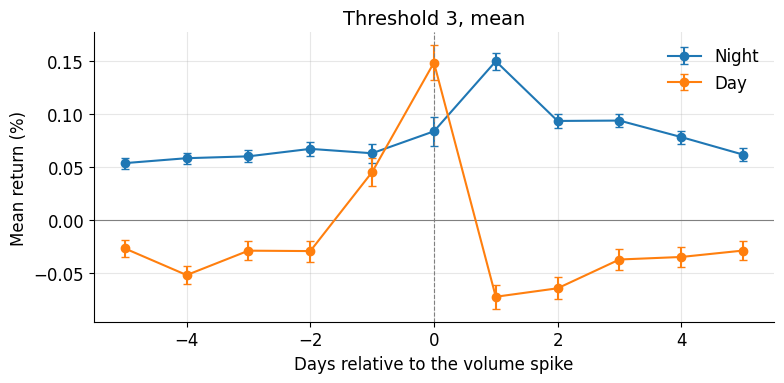

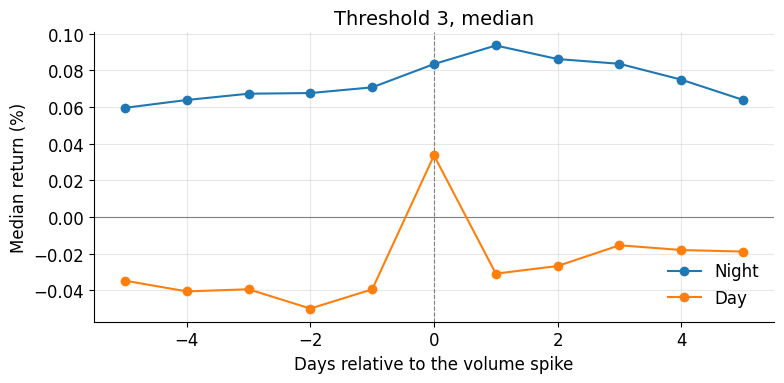

In [ ]:
fig = plot_event_study(result, stat="mean", title="Threshold 3, mean")
fig = plot_event_study(result, stat="median", title="Threshold 3, median")

Before the spike, nights earn about +0.06% and days about −0.03%. On day +1 the overnight return rises to +0.15% and the intraday return falls to −0.07%. The median confirms the overnight jump but not the intraday drop, which comes from a minority of events with large losses.

## V.3 Larger spikes : does the effect grow with attention ?

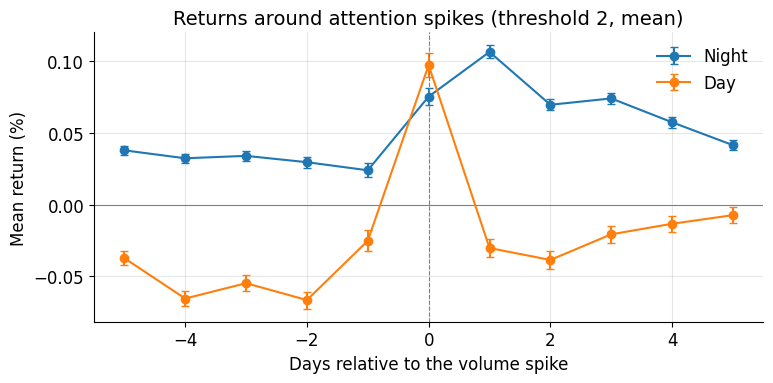

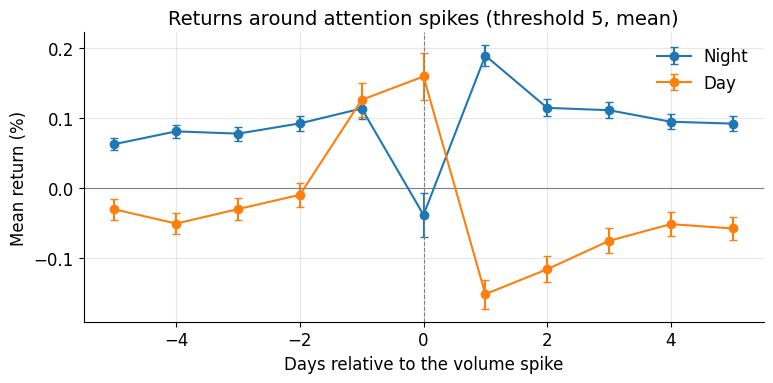

In [ ]:
for t in [2, 5]:
    res = event_study(abnormal_volume(prices, threshold=t), drop_flags=flags)
    fig = plot_event_study(res, stat="mean", title=f"Returns around attention spikes (threshold {t}, mean)")

| Threshold | Night +1 (before the spike) | Day +1 (before the spike) |
|---|---|---|
| 2 | +0.11% (+0.03%) | -0.03% (-0.06%) |
| 3 | +0.15% (+0.06%) | -0.07% (-0.04%) |
| 5 | +0.19% (+0.08%) | -0.15% (-0.03%) |

The effect grows with the size of the spike. At threshold 2 there is an overnight jump but no intraday reversal; at threshold 5 the day +1 overnight return reaches +0.19% and the intraday return −0.15%. The largest spikes also come after a negative night and a positive day −1, which points to news.


## V.4 Google Trends

Search volume on Google could be a more direct measure of attention than trading volume, so we tried it with `pytrends` on ten large companies between January and March 2020.

**Searching for the company name** alone ("Apple") does not work well: it mostly reflects interest in the brand and hardly moves during the COVID crash. "Apple stock" is much better. It falls every weekend, jumps around Apple's earnings at the end of January and rises sharply in March 2020.

There are some practical limits. Daily values are only returned for **short windows** (a two-year request gives weekly data), and each request is rescaled between 0 and 100, so values can only be compared within the same window. `pytrends` is not an official API; our ten requests went through without being blocked, but this may change with many more.

For P3 we plan to use "*X* stock" for around 30 large companies, in short windows around volume spikes, and compare each day to the average of its window. If this does not work at scale, we will keep abnormal volume as our measure of attention.

## Conclusion

**Preliminary finding:** the crowd remains a credible suspect, and the one P3 investigates most.

- **Overnight gain (V.2):** after an attention spike, the next overnight return is well above its normal level, in both the mean and the median.
- **Intraday reversal (V.2):** on average, the next intraday return is below its normal level, but the typical event shows no reversal; the average effect comes from a subset of events.
- **Dose-response (V.3):** both the overnight gain and the intraday reversal grow with the size of the spike.

The suspect is not convicted. A volume spike often comes with news, so this analysis shows that attention **comes with** a hangover, not that attention alone **causes** it. The effect is also small, about 0.1 percentage point per night, so it is unclear whether it could be exploited after transaction costs.

## Next steps for P3

1. Separate news from attention:

   Split spikes into those with and without an 8-K filing (Part IV), and use confused tickers as a natural experiment (Part VI).

2. Google Trends:

   Measure search interest around spikes for about 30 large companies.

3. Market-adjusted returns:

   Subtract the market's overnight and intraday returns of the same day, since spikes cluster on market-wide days.

4. Correct confidence intervals:

   Spikes on the same date are not independent, so the current intervals are too narrow; we will cluster them by date.

5. Which events reverse:

   Compare the reversal across spike size, stock size and liquidity.

6. Transaction costs:

   Check whether the effect survives realistic trading costs.

# Part VI - The Proof: Confused Tickers (preliminary results)

**Where we stand:** The project asks who makes prices rise overnight. Part III found no sign that longer nights pay more, so two suspects remain:
- **news** (Part IV): information about the value of a company (earnings, a merger...), which we observe through its SEC 8-K filings;
- **the crowd** (Part V): investors who buy because they have noticed a company (an article, social media, television).

**The problem:** For an ordinary stock, or one of a large well-known company, a spike of attention (a day with unusually high volume) often has several causes at once: a published piece of news (an 8-K filing), media coverage of the company that brings in a crowd of investors, and so on. It is therefore hard to isolate the crowd and to know whether it can move prices on its own: this is a confounder (in the sense of lecture 6).

**The idea:** a natural experiment. The investors brought in by a piece of news who read the 8-K are very unlikely to mistake the ticker: it appears on the filing, and they are often experienced investors. By contrast, an 8-K that makes the buzz (media coverage: articles, television, social media), or simply a company that is the talk of the day without any 8-K, brings in the crowd, and the crowd can easily mistake tickers: it is not necessarily expert and has not checked the ticker of the company. Our experiment therefore takes a large company A that can be mistaken for a small company B (the *confused stock*, such as `ZOOM` and `ZM`, see the example below), looks at the spikes of attention of A, and looks at their impact on B. Since the 8-Ks are mostly read by experts, if the attention around A carries over to B, then under our hypothesis it is mainly the crowd. If B then gains more than usual overnight, this would show that the crowd alone can cause an overnight rise in prices; if not, we detect nothing.

**Hypotheses:** The experiment relies on four hypotheses: (1) the 8-Ks are mostly read by experienced investors, who rarely mistake the ticker; (2) a large part of the buying of B really comes from the mix-up (some may be genuine buyers of B); (3) A and B are unrelated companies; (4) B has no news of its own on the event days (we do not check it yet, see the limits).

**The example of `ZOOM`:** Zoom Video Communications, a well-known company, trades under `ZM`. In March 2020, during the COVID-19 lockdown, everyone was talking about it, and investors bought `ZOOM` by mistake, the ticker of Zoom Technologies, an unrelated small company traded over the counter, whose price soared. The SEC suspended its trading on 26 March 2020, fearing that investors were buying the wrong company ([Law360](https://www.law360.com/securities/articles/1257356/sec-cuts-zoom-stock-boom-short-fearing-name-confusion), [Bloomberg Law](https://news.bloomberglaw.com/securities-law/zoom-technologies-trading-suspended-amid-ticker-confusion), [Fortune](https://www.fortune.com/2020/03/26/zoom-stock-halt-zm-ticker)). Here A is `ZM` and B is `ZOOM`. `ZOOM` is missing from our dataset because of survivorship bias: it only contains securities still listed in 2020 (Part I). So we look for similar cases.

**What we measure:** As in Part V, a day is an attention spike when its volume is more than three times its average over the previous 20 days; the events are the spikes of A. For B we look at two things: its volume (does the attention of A reach it?) and its overnight return into the next session, compared with its usual overnight return and with placebo stocks (stocks as large as A, whose spikes have nothing to do with B). Under our hypotheses, a gain overnight would come from the crowd.

**Research question:** When a well-known company has a spike of attention, does the stock that investors mistake for it gain more than usual overnight, compared with placebo stocks?

**Roadmap:** VI.1 looks for stocks that can be mistaken for each other. VI.2 studies one case, `FORD` and `F`. VI.3 asks whether the result is more than chance, before the conclusion.

In [2]:
from src.analysis.confusion import (
    PAIR_FLAGS,
    case_summary,
    load_pair,
    one_letter_pairs,
    pair_placebo_test,
    pair_summary,
    pairs_by_min_length,
    ticker_coverage,
    ticker_name_matches,
    twin_events,
    usual_overnight_return,
)
from src.analysis.crowd import event_study
from src.config import STUDY_START_YEAR
from src.data.load import load_prices
from src.data.metadata import load_metadata
from src.visualization.confusion import (
    plot_overnight_event_study,
    plot_pair_density,
    plot_pairs_by_length,
    plot_placebo_scores,
)

## VI.1 Finding stocks that can be mistaken for each other

We test two ways of finding such stocks: tickers that are one letter apart, and a ticker that is the name of another company (`ZOOM` is the name of Zoom Video).

### VI.1.a Tickers that are one letter apart

The **edit distance** (Levenshtein) $d(a, b)$ between two tickers is the minimum number of single-letter replacements, insertions or deletions that turn $a$ into $b$. It follows the recursion
$$d_{i,j} = \min\big(d_{i-1,j} + 1,\; d_{i,j-1} + 1,\; d_{i-1,j-1} + \mathbb{1}[a_i \neq b_j]\big), \qquad d_{i,0} = i,\; d_{0,j} = j.$$
We keep the pairs with $d = 1$ among the 8,049 tickers of the dataset (about 32 million comparisons, done with `rapidfuzz`).

In [3]:
coverage = ticker_coverage(load_prices(columns=["ticker", "date"]))
pairs = one_letter_pairs(coverage.index.tolist())
pair_summary(pairs, n_tickers=len(coverage))

pairs                     46552
substitutions             36137
insertions / deletions    10415
tickers involved           7835
share of tickers (%)       97.3
dtype: object

Number of one-letter pairs by the length of the shorter ticker:

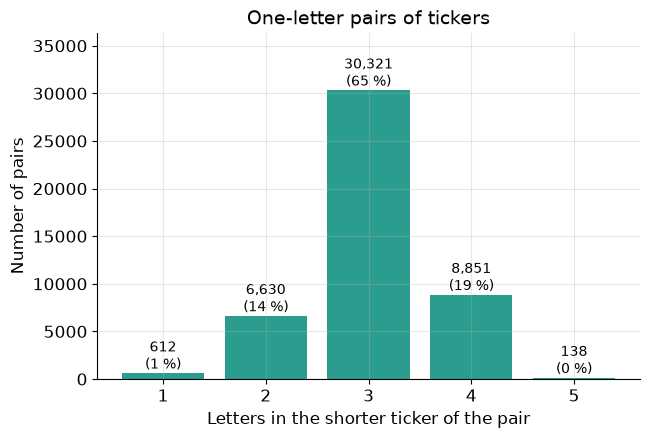

In [4]:
fig = plot_pairs_by_length(pairs_by_min_length(pairs))

**Takeaway:** This method does not help us choose. Almost every ticker has a neighbour: 97.3 % of the tickers are in at least one pair. Of the 46,552 pairs, 30,321 (65 %) involve a ticker of three letters, and 84 % a ticker of three or four. Most pairs are short tickers that differ by one letter by chance, with no reason for anyone to mistake one for the other. A list that contains nearly all the tickers cannot point to the pairs that are really mistaken. The method also misses our model case: `ZM` and `ZOOM` differ by two letters.

### VI.1.b Tickers that look like the name of another company

An investor who wants *Zoom* searches for the word "zoom". We therefore say that a ticker $T$ matches a company if one word $w$ of its name is identical to it, $d(T, w) = 0$. To keep the list readable we ignore short tickers (under four letters), legal words and common words, we search names only in the main security of a company (not its preferred shares or notes), we skip ETFs of the same fund family, and we require the two stocks to be listed together for at least 90 days. Without the filters on length, common words, main securities, fund families and common listing, the comparison gives 3,516 matches; **with them, 94 matches remain** (77 different tickers).

In [5]:
meta = load_metadata()
matches = ticker_name_matches(meta, coverage)
print(f"{len(matches)} matches, {matches['ticker'].nunique()} different tickers")

94 matches, 77 different tickers


In [6]:
# Selected name matches illustrate candidates, including ambiguous/common-word cases.
examples = ["FORD", "SNAP", "MGIC", "ICON", "ZION", "TEAM", "PENN", "BBVA", "FIVE"]
columns = {
    "ticker": "ticker B", "ticker_name": "confused company B",
    "owner_name": "confused with company A", "owner": "ticker A"
}
matches.loc[matches["ticker"].isin(examples), list(columns)].rename(columns=columns).reset_index(drop=True)

,ticker B,confused company B,confused with company A,ticker A
0,BBVA,Banco Bilbao Vizcaya Argentaria S.A. Common Stock,Banco BBVA Argentina S.A. ADS,BBAR
1,FIVE,"Five Below, Inc. - Common Stock","Five Point Holdings, LLC Class A Common Shares",FPH
2,FIVE,"Five Below, Inc. - Common Stock","Five Prime Therapeutics, Inc. - Common Stock",FPRX
3,FORD,"Forward Industries, Inc. - Common Stock",Ford Motor Company Common Stock,F
4,ICON,"Iconix Brand Group, Inc. - Common Stock",ICON plc - Ordinary Shares,ICLR
5,MGIC,Magic Software Enterprises Ltd. - Ordinary Shares,MGIC Investment Corporation Common Stock,MTG
6,PENN,"Penn National Gaming, Inc. - Common Stock",Mid Penn Bancorp - Common Stock,MPB
7,PENN,"Penn National Gaming, Inc. - Common Stock",Penn Virginia Corporation - Common Stock,PVAC
8,SNAP,Snap Inc. Class A Common Stock,Snap-On Incorporated Common Stock,SNA
9,TEAM,Atlassian Corporation Plc - Class A Ordinary S...,"Team, Inc. Common Stock",TISI


**Takeaway:** The 94 matches are **candidates**, not proofs: some are a brand of an unrelated company (`FORD` and Ford Motor, `SNAP` and Snap-On), others are companies of the same group (`BBVA`) or common words (`FIVE`).

**Our case:** `FORD` / `F` is the candidate that looks most like `ZOOM` / `ZM`: the ticker `FORD` is the brand of a very well-known company, easy to mistake, and the press reported the mix-up (VI.2). Unlike `ZOOM`, both stocks are in the dataset. We chose it by reading the list of candidates, **before** looking at any of its returns, and VI.2 studies it.

## VI.2 One case: `FORD` and `F`

We ask whether the attention of `F` reaches `FORD`, and whether `FORD` gains more than usual overnight after the spikes of `F`. In our data, `F` is Ford Motor Company, the well-known company (A), and `FORD` is Forward Industries (B), a much smaller and unrelated company. The press reported that investors bought `FORD` by mistake whenever Ford Motor was in the news ([Ford Authority](https://fordauthority.com/2019/08/investors-keep-buying-the-wrong-ford-stock/), [CNN](https://edition.cnn.com/2019/08/12/investing/ticker-symbol-confusion)).

We use the attention measure of V.1: a day is a **spike** of `F` when its abnormal volume is above 3.

In [7]:
# FORD/F is the documented confusion case selected before examining its returns.
case = load_pair("F", "FORD")
study = case[case["date"].dt.year >= STUDY_START_YEAR]
case_summary(study, "F", "FORD")

,FORD,F
first day,1998-01-02,1998-01-02
last day,2020-04-01,2020-04-01
days,5598,5598
median close ($),1.75,12.36
median volume (shares),26800,28050100
median dollar volume ($),49739,300345730
days without volume (%),0.9,0.0
open = previous close (%),19.5,9.2
open = close (%),14.0,3.3


The table above shows how small `FORD` is: it trades about \$50,000 a day, against \$300 million for `F`, and on 19.5 % of its days its open is simply the previous close (no real opening trade). Since 1998, `F` has 51 spikes, and `FORD` has a row on each of them. **Does the attention of `F` reach `FORD`?** Does `FORD` also trade more when `F` has a spike? The density below compares the abnormal volumes of the two stocks on the same days. Each day is placed by the abnormal volume of `F` (horizontal) and of `FORD` (vertical), on log scales where 1 is a usual day; darker cells hold more days, and the orange dots are the 51 spike days of `F`. If `FORD` traded more when `F` does, the dots would sit above the dense zone:

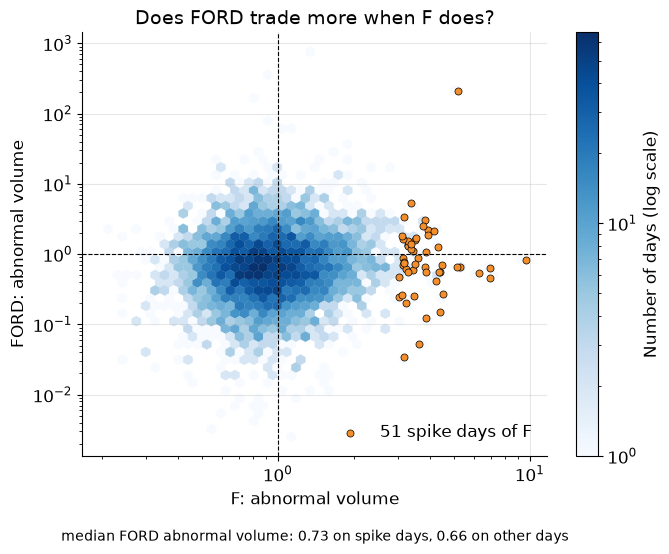

In [8]:
fig = plot_pair_density(study, "F", "FORD")

**Takeaway:** The orange dots are further right than the other days, since a spike of `F` is defined by its volume, but they sit at the same height: `FORD` is no more active on those days. The median abnormal volume of `FORD` is 0.73 on the spike days of `F` and 0.66 on the other days, and `FORD` trades above its usual level on 39 % of the spike days against 33 % of the others. `FORD` barely trades more when `F` does, so the attention of `F` does not clearly reach `FORD`: this weakens the test.

We now look at the returns of `FORD` around the spikes of `F`.

**Event study:** As in V.2, but day 0 is a spike day of `F` and day $k$ is the $k$-th trading day of `FORD`; the night of interest is again the one **into day +1**.

**Sample:** We clean `FORD` with the light filter of Part I and we remove the days when it has no real opening trade (its open equals the previous close: the stale-open flag of I.6, also removed in Part V), because its overnight return is then wrong. **We do not use the liquidity filter of Part I**: it removes small, little-traded stocks, which are exactly the confused stocks. Of the 51 spikes of `F` since 1998, 8 fall on a day when `FORD` has no real opening trade: we drop them, which leaves 43 events. Among these, only 34 can be studied on day +1, because `FORD` also needs a real opening trade on that day. The result on day +1 therefore rests on 34 events, which limits what this single case can show.

The figure shows, for each day, the mean overnight return of `FORD` and its 95 % confidence interval. The reference is not zero but the usual overnight return of `FORD` (dashed line): when a bar crosses it, the mean cannot be told apart from it. The table then gives days 0 and +1, with the half-width of the interval (`ci95`) and the number of events (`n`):

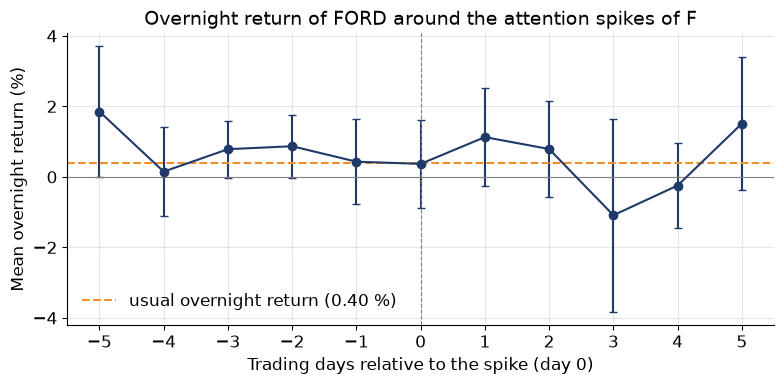

In [9]:
result = event_study(twin_events(case, "F", "FORD"), drop_flags=PAIR_FLAGS)
usual = usual_overnight_return(case, "FORD")
fig = plot_overnight_event_study(result, usual, title="Overnight return of FORD around the attention spikes of F")

In [10]:
# Day 0 is the spike; day +1 contains the overnight return after that spike.
result[(result["return"] == "r_night") & result["day"].isin([0, 1])]

,day,return,mean,median,ci95,n
10,0,r_night,0.003680,0.004619,0.012532,43
12,1,r_night,0.011273,0.009527,0.013851,34


**Takeaway:** On day +1, `FORD` has a mean overnight return of +1.1 % (from −0.3 % to +2.5 %). Compared with its usual +0.4 %, this is an excess of about +0.7 points, with an interval from −0.7 to +2.1 points that includes zero: we cannot tell it from chance. This is a **sign, not a result**: other nights move as much (+1.9 % on day −5, +1.5 % on day +5), there are only 34 events, and the intervals treat events as independent. The placebo of VI.3 is what can give this sign a meaning.

## VI.3 Is it more than chance?

`FORD` might gain more than usual overnight after the spikes of any large stock, not only after those of `F`. On days when many stocks spike at once (market-wide days, index rebalancing), many stocks move in the same way. A **placebo** tells us how large the overnight gain is by chance: we repeat the measure with the spikes of other stocks as large as `F`.

**Score:** To compare with placebos we need a single number, fixed in advance. Let $\bar r^{\,\text{night}}_{+1}$ be the mean overnight return of `FORD` on day +1 after an event, and $\bar r^{\,\text{night}}$ its mean over all its sessions. The score is the excess overnight gain
$$S = \bar r^{\,\text{night}}_{+1} - \bar r^{\,\text{night}},$$
positive when `FORD` gains more than usual overnight after the events. We use the overnight gain because it is the question of the project.

**Placebo and p-value:** We compute $S$ with the spikes of `F`, then with the spikes of each of the $n = 100$ liquid stocks whose size (median daily dollar volume) is the closest to that of `F`: these are the placebo companies. The one-sided p-value is
$$p = \frac{1 + \#\{\,S_{\text{placebo}} \ge S_{\text{observed}}\,\}}{1 + n}.$$
Events and returns are taken from 1998, as in Part V.

The table below gives the score of `FORD` after the spikes of `F` and the average score of the placebo companies. In the figure, each bar counts the placebo companies with a given score, and the orange line marks the score after the spikes of `F`.

In [11]:
test = pair_placebo_test("FORD", "F")
placebo = test["placebo_scores"]
pd.Series({
    "events of F": test["n_events"],
    "score of FORD (points)": 100 * test["score"],
    "mean placebo score (points)": 100 * placebo.mean(),
    "placebo companies at least as large": int((placebo >= test["score"]).sum()),
    "p-value": test["p"],
})

events of F                            34.000000
score of FORD (points)                  0.725763
mean placebo score (points)            -0.040460
placebo companies at least as large    16.000000
p-value                                 0.168317
dtype: float64

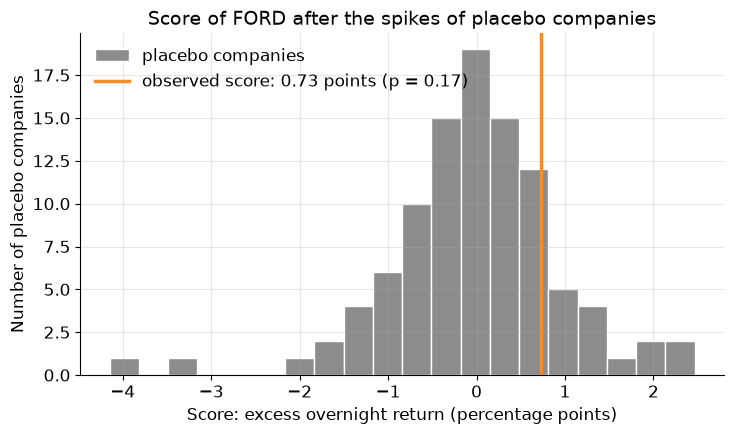

In [13]:
fig = plot_placebo_scores(placebo, test["score"], test["p"], title="Score of FORD after the spikes of placebo companies")

**Takeaway:** `FORD` has a score of 0.7 points after the spikes of `F`, against about 0 on average after those of the placebo companies. 16 of the 100 placebo companies do at least as well: **p = 0.17**. `FORD` gains more overnight after the spikes of `F` than after those of other large stocks, but not significantly: the scores of the placebo companies themselves vary a lot (a standard deviation of 1.0 point), and there are only 34 events.

## Conclusion

**Preliminary finding:** the test is feasible, but a first run on one case detects no effect; P3 needs more cases before concluding.

- **The test can be run (VI.1):** matching tickers with company names gives 94 candidate pairs. `ZOOM` is missing from the dataset (survivorship bias), so we study `FORD` / `F`.
- **No clear effect on this case (VI.2–VI.3):** after the spikes of `F`, `FORD` gains about 0.7 points more than usual overnight, but 16 of the 100 placebo companies do at least as well (p = 0.17), and its volume does not clearly rise on those days.

This part therefore **neither confirms nor rejects** that the crowd alone produces the overnight gain.

The test also has limits: one case and 34 events; `FORD` is small and little traded, so its opens are noisy; we do not check whether `FORD` published news (an 8-K) on the event days; a null result is ambiguous, since either the crowd alone does not move a price, or the attention of `F` does not reach `FORD`. All results are associations, not causes.

## Next steps for P3

In this part we tested a single case, `FORD` / `F`, only to check that the experiment is possible. The goal of P3 is to try to isolate the crowd with this experiment in several other documented cases of ticker confusion:

1. Find more documented cases in our dataset:

   Search the press, the SEC trading suspensions and the literature for mix-ups between two tickers that are both in the dataset.

2. Study each case as we did for `FORD` / `F`:

   Look at the volume of the confused stock, its overnight return around the spikes of the well-known company, and a placebo.

3. Strengthen each study:

   With the 8-K data of Part IV, drop the events where the confused stock has a filing of its own and split the spikes of the well-known company with and without an 8-K; adjust for the days when many stocks spike together and cluster the confidence intervals by date.

4. Decide:

   If even with more cases the test lacks power, this part is reduced to a discussion of what daily data can and cannot show, and we say so.

# References

- Cliff, M., Cooper, M. J. and Gulen, H. (2008). Return differences between trading and non-trading hours: Like night and day. Working paper, Virginia Tech.
- Frazzini, A. and Lamont, O. A. (2007). The earnings announcement premium and trading volume. NBER Working Paper 13090.
- French, K. R. (1980). Stock returns and the weekend effect. *Journal of Financial Economics*, 8(1), 55–69.
- Lucca, D. O. and Moench, E. (2015). The pre-FOMC announcement drift. *Journal of Finance*, 70(1), 329–371.
- Savor, P. and Wilson, M. (2013). How much do investors care about macroeconomic risk? *Journal of Financial and Quantitative Analysis*, 48(2), 343–375.